# Controller design for the three gantry axes (firmware 2.2 structure)

**Goal.** Derive the gains of the controller that already runs on the ESP32-C3 for each axis, from the plants identified in
`report_method_analyses_new_tests.ipynb`, and check them against CTRL-03, CTRL-04, CTRL-07, CTRL-08 and MECH-09 over the parametric uncertainty of the plant.
The structure is **kept as it is in firmware 2.2**, one-sided and saturated, so the gains can be pasted into `SET GAIN`:

$$u[k]=\mathrm{clamp}\big(V_0+K_p\,e[k]-K_d\,\hat v[k]+n[k],\;0,\;V_{lim}\big),\qquad e[k]=D-N[k]\,\ell,\quad \hat v[k]=\frac{\ell}{\max(T_{tick},\,t-t_{last})}$$

with $\ell$ the distance per count (1.066 mm on X and Y, 0.267 mm on Z), $N$ the pulse count, $n$ the stall nudge, a 5 ms update, a 50 V/s slew limit,
and braking as soon as $e\le\ell$ ("stops within one count"). Gain format in the firmware: `gain_<axis> = [Kp, Kd, Vlim, V0]`.

**Method (CTRL-03):** 1. plant and uncertainty box per axis (S domain); 2. closed-loop poles in S, a first design; 3. discretisation at 5 ms with the actuation delay (Z domain);
4. the non-linear firmware law (one-sided drive, dead band, 1 count quantisation, tick-timing speed, stop band) simulated on a grid of plants, and the gains searched on that grid;
5. the chosen gains verified on the full uncertainty grid against each requirement.

**Status of the numbers.** Every plant number comes from `results_new_tests/`. Values that are *assumed* because the data cannot give them are listed in Section 1 and are
marked pending bench identification in the write-up (Z from two clean voltages and a jerky 8 V point, τ only bounded on X and Z, brake and nudge behaviour taken from the firmware notes, not from the source).

In [1]:
from pathlib import Path
import sys, warnings, itertools, time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy import signal
from scipy.ndimage import minimum_filter
from IPython.display import Markdown, display

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
from ctrl_sim import simulate

FIG = HERE / 'figures_controllers'
RES = HERE / 'results_controllers'
INP = HERE / 'inputs'
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#a3a29c', '#e4e3df', '#fcfcfb'
AXC = {'X': '#2a78d6', 'Y': '#eb6834', 'Z': '#1baf7a'}
BAD = '#c0392b'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight', 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'savefig.facecolor': SURFACE, 'font.size': 9, 'axes.titlesize': 9.5, 'axes.titleweight': 'bold', 'axes.labelsize': 9,
    'legend.fontsize': 8, 'axes.edgecolor': INK_2, 'axes.labelcolor': INK, 'axes.titlecolor': INK, 'xtick.color': INK_2,
    'ytick.color': INK_2, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.4, 'legend.frameon': False, 'axes.axisbelow': True,
})

def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()

def note(ax, text, loc='tl', fs=7.8):
    x, y, ha, va = {'tl': (0.02, 0.97, 'left', 'top'), 'tr': (0.98, 0.97, 'right', 'top'),
                    'bl': (0.02, 0.03, 'left', 'bottom'), 'br': (0.98, 0.03, 'right', 'bottom')}[loc]
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, color=INK_2, fontsize=fs)

## 1. Plants, uncertainty boxes and requirements

**Plant (S domain).** From the identification, each axis is an affine speed law with a dead band and a first-order lag. With input $u$ (V) and carriage position $x$ (mm):

$$\tau\,\dot v + v = K\,(u-V_{db})_+ ,\qquad \dot x = v \quad\Rightarrow\quad G(s)=\frac{X(s)}{U(s)}=\frac{K}{s(\tau s+1)}\ \ (u>V_{db})$$

**Uncertainty box.** The load is a disturbance and the motor model is uncertain (CTRL-03), so the controller is checked on a box of $K$, $\tau$, $V_{db}$, actuation delay and breakaway voltage.
$K$ and $\tau$ come from the envelope of the identification (`uncertainty_envelope.csv`). The other edges are decisions, listed in the table.

In [2]:
ident = pd.read_csv(INP / 'axis_identification.csv').set_index('axis')
env = pd.read_csv(INP / 'uncertainty_envelope.csv').set_index('axis')
inc = pd.read_csv(INP / 'incremental_gain_by_direction.csv')

SLOT = {'X': 1.0661, 'Y': 1.0661, 'Z': 0.2667}          # mm per count
TRAVEL = {'X': 620.0, 'Y': 1000.0, 'Z': 250.0}          # mm (MECH-04: X +-0.31 m, Y 1.0 m of bed, Z 0 to 0.25 m)
MOVES_SPEC = {'X': [3, 10, 25, 50], 'Y': [3, 10, 25, 50], 'Z': [3, 5, 10, 25, 50]}
TIME_D = {'X': 50.0, 'Y': 50.0, 'Z': 5.0}                # longest move that must settle within 3 s (Z: at 5 V the carriage moves at most 7 mm/s, so 50 mm is physically out of reach, see Section 6)
OVER_SPEC, SETTLE_SPEC, T_TRAV = 1.1, 3.0, 30.0
# assumed edges (not identified): V_db range, delay range, breakaway excess
VDB_SPREAD = {'X': (-0.3, 0.3), 'Y': (-0.2, 0.5), 'Z': (-0.4, 0.4)}
DELAYS = (5.0, 15.0, 30.0)                              # ms, one 5 ms update plus L298 and motor electrical lag, up to 30 ms
DVB = (0.0, 0.3)                                        # V of extra voltage to break away from rest

BOX = {}
for a in 'XYZ':
    e = env.loc[a]
    tau_hi = e.tau_hi_ms / 1e3
    BOX[a] = dict(K=(e.K_lo, e.K_design, e.K_hi), tau=(e.tau_lo_ms / 1e3, np.sqrt(e.tau_lo_ms / 1e3 * tau_hi), tau_hi),
                  Vdb=tuple(float(ident.loc[a, 'V_db']) + d for d in (VDB_SPREAD[a][0], 0.0, VDB_SPREAD[a][1])))
    BOX[a]['Vdb0'] = float(ident.loc[a, 'V_db'])
    BOX[a]['Kd_unit'] = 1.0 / float(ident.loc[a, 'K_mm_s_per_V'])

# Z above 5 V: the mean speed at 8 V (firmware count over run time) is well below the 3.5-5 V line and the motion is jerky (6-14 mm/s within a run).
# Modelled as a knee at 5 V, above which the speed gain per volt is K2; it only matters for Z gains with Vlim above 5 V (the design uses 5 V).
_c = pd.read_csv(INP / 'runs_first_order.csv')
_c = _c[(_c.axis == 'Z') & (_c.run != 'Z 3.5 V neg')]                      # the first Z 3.5 V neg run stalled
_z5, _z8 = (_c[_c.volts == v].vss.abs().mean() for v in (5.0, 8.0))
KNEE = {'Z': dict(Vk=5.0, K2=float((_z8 - _z5) / 3.0), v5=float(_z5), v8=float(_z8))}

rows = []
for a in 'XYZ':
    b = BOX[a]
    rows.append({'axis': a, 'K lo / nom / hi (mm/s/V)': ' / '.join(f'{v:.2f}' for v in b['K']),
                 'tau lo / mid / hi (ms)': ' / '.join(f'{v*1e3:.0f}' for v in b['tau']),
                 'V_db lo / nom / hi (V)': ' / '.join(f'{v:.2f}' for v in b['Vdb']),
                 'count (mm)': SLOT[a], 'travel (mm)': TRAVEL[a]})
display(pd.DataFrame(rows).set_index('axis'))
display(Markdown(
    f"* **delay** {DELAYS[0]:.0f}, {DELAYS[1]:.0f}, {DELAYS[2]:.0f} ms and **breakaway excess** {DVB[0]:.1f} and {DVB[1]:.1f} V on top of $V_{{db}}$ (assumed, not identified).\n"
    "* **Why these $V_{db}$ edges.** X is at the identified value ±0.3 V and Z ±0.4 V (the Z fits for the two directions agree within 0.07 V, but there are only two voltages); Y gets +0.5 V on the high side because Y at 3.5 V "
    "stalled in two of four runs while $V_{db}$ = 3.09 V, so the local friction on some stretch of the rail exceeds the average.\n"
    "* **Z K and τ** are the envelope of the new Z recordings: K 1.5-2.7 mm/s per V (the low edge is the 8 V runs) and τ 17-142 ms. τ is still only bounded; τ × 1.5 is applied afterwards as a stress test (Section 8).\n"
    f"* **Z above 5 V.** The 8 V runs average {KNEE['Z']['v8']:.1f} mm/s against {2.5584909 * 5.7:.1f} predicted by the 3.5 and 5 V line and alternate between about 6 and 14 mm/s inside a run, so Z is modelled with a knee at 5 V (speed gain per volt above it {KNEE['Z']['K2']:.2f} mm/s per V) and the Z design is limited to $V_{{lim}}$ = 5 V, "
    "where the identified law holds. Section 8 shows what a higher limit would do in the model.\n"
    "* **Requirements checked:** CTRL-04 settle ≤ 3 s within one count for moves ≤ 50 mm; CTRL-07 overshoot ≤ 1.1 mm and no reversal of the drive; CTRL-08 timeout 15 s + distance / 3 mm/s (1 mm/s on Z) and soft limits 5 mm inside the ends; MECH-09 Y 1 m in ≤ 30 s."))

,K lo / nom / hi (mm/s/V),tau lo / mid / hi (ms),V_db lo / nom / hi (V),count (mm),travel (mm)
axis,,,,,
X,9.06 / 9.51 / 9.99,14 / 47 / 159,1.71 / 2.01 / 2.31,1.0661,620.0
Y,8.31 / 9.89 / 11.86,15 / 28 / 54,2.89 / 3.09 / 3.59,1.0661,1000.0
Z,1.49 / 2.56 / 2.66,17 / 49 / 142,1.90 / 2.30 / 2.70,0.2667,250.0


* **delay** 5, 15, 30 ms and **breakaway excess** 0.0 and 0.3 V on top of $V_{db}$ (assumed, not identified).
* **Why these $V_{db}$ edges.** X is at the identified value ±0.3 V and Z ±0.4 V (the Z fits for the two directions agree within 0.07 V, but there are only two voltages); Y gets +0.5 V on the high side because Y at 3.5 V stalled in two of four runs while $V_{db}$ = 3.09 V, so the local friction on some stretch of the rail exceeds the average.
* **Z K and τ** are the envelope of the new Z recordings: K 1.5-2.7 mm/s per V (the low edge is the 8 V runs) and τ 17-142 ms. τ is still only bounded; τ × 1.5 is applied afterwards as a stress test (Section 8).
* **Z above 5 V.** The 8 V runs average 10.0 mm/s against 14.6 predicted by the 3.5 and 5 V line and alternate between about 6 and 14 mm/s inside a run, so Z is modelled with a knee at 5 V (speed gain per volt above it 1.05 mm/s per V) and the Z design is limited to $V_{lim}$ = 5 V, where the identified law holds. Section 8 shows what a higher limit would do in the model.
* **Requirements checked:** CTRL-04 settle ≤ 3 s within one count for moves ≤ 50 mm; CTRL-07 overshoot ≤ 1.1 mm and no reversal of the drive; CTRL-08 timeout 15 s + distance / 3 mm/s (1 mm/s on Z) and soft limits 5 mm inside the ends; MECH-09 Y 1 m in ≤ 30 s.

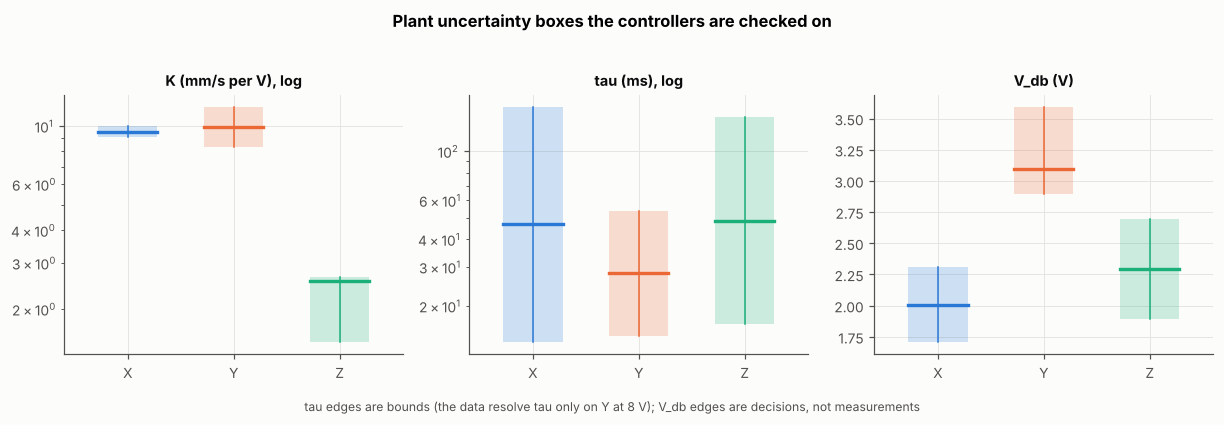

In [3]:
# --- Figure D1: identified plant boxes, one panel per parameter ---
fig, axs = plt.subplots(1, 3, figsize=(11.2, 3.4))
for ax, key, lab, scale in zip(axs, ('K', 'tau', 'Vdb'), ('K (mm/s per V)', 'tau (ms)', 'V_db (V)'), (1, 1e3, 1)):
    for i, a in enumerate('XYZ'):
        lo, mid, hi = (np.array(BOX[a][key]) * scale)
        ax.add_patch(Rectangle((i - 0.28, lo), 0.56, hi - lo, color=AXC[a], alpha=0.22, lw=0))
        ax.plot([i - 0.28, i + 0.28], [mid, mid], color=AXC[a], lw=2.2)
        ax.plot([i, i], [lo, hi], color=AXC[a], lw=1.0)
    ax.set_xticks(range(3)); ax.set_xticklabels(list('XYZ')); ax.set_xlim(-0.6, 2.6)
    ax.set_title(lab)
    if key in ('K', 'tau'):
        ax.set_yscale('log')
axs[0].set_title('K (mm/s per V), log')
axs[1].set_title('tau (ms), log')
fig.text(0.5, -0.04, 'tau edges are bounds (the data resolve tau only on Y at 8 V); V_db edges are decisions, not measurements', ha='center', color=INK_2, fontsize=8)
fig.suptitle('Plant uncertainty boxes the controllers are checked on', y=1.03, fontweight='bold')
fig.tight_layout()
save(fig, 'D1_plant_boxes.png')

## Helper functions: scenario grids and requirement metrics

One scenario is a plant corner, an actuation delay, a breakaway voltage, a move length and a start phase (where the true start lies inside a count). All scenarios of a candidate are
simulated in one vectorised call. A scenario **fails** when it does not finish within the firmware timeout (15 s + distance / 3 mm/s, Z 1 mm/s), settles later than 3 s, ends more than one count short or
overshoots by more than 1.1 mm of feedback position. The feedback position is the pulse count × count length, which is what the firmware sees and logs.

In [4]:
def timeout_s(a, D):
    return 15.0 + D / (1.0 if a == 'Z' else 3.0)

def scen_grid(a, moves, level='full', seed=0, n_phase=3, Dfrac=True):
    """Return dict of scenario arrays (without gains) for axis a."""
    b = BOX[a]
    if level == 'full':
        Ks, taus, Vdbs, dl, dvb = b['K'], b['tau'], b['Vdb'], DELAYS, DVB
    elif level == 'coarse':
        Ks, taus, Vdbs, dl, dvb = (b['K'][0], b['K'][2]), b['tau'], b['Vdb'], (DELAYS[0], DELAYS[2]), DVB
        n_phase = 2
    elif level == 'nominal':
        Ks, taus, Vdbs, dl, dvb = (b['K'][1],), (b['tau'][2],), (b['Vdb'][1],), (DELAYS[1],), (DVB[1],)
        n_phase = 1
    rng = np.random.default_rng(seed)
    combos = list(itertools.product(Ks, taus, Vdbs, dl, dvb, range(n_phase), moves))
    c = np.array(combos, float)
    N = len(c)
    D = c[:, 6] + (rng.random(N) * SLOT[a] if Dfrac else 0)
    S = dict(K=c[:, 0], tau=c[:, 1], Vdb=c[:, 2], delay_ms=c[:, 3], dVb=c[:, 4],
             frac0=(c[:, 5] + rng.random(N)) / n_phase, D=D, D0=c[:, 6], slot=np.full(N, SLOT[a]))
    if a in KNEE:
        S['Vk'] = np.full(N, KNEE[a]['Vk']); S['K2'] = np.minimum(S['K'], KNEE[a]['K2'])
    return S

def run_scen(S, gains, t_max=20.0, record=0, **kw):
    """gains: (Kp, Kd, V0, Vlim) scalars OR arrays of length len(S['K'])."""
    N = len(S['K'])
    P = {k: S[k] for k in ('K', 'tau', 'Vdb', 'dVb', 'delay_ms', 'D', 'frac0', 'slot', 'Vk', 'K2') if k in S}
    for name, g in zip(('Kp', 'Kd', 'V0', 'Vlim'), gains):
        P[name] = np.full(N, g, float) if np.isscalar(g) else np.asarray(g, float)
    return simulate(P, t_max=t_max, record=record, **kw)

def judge(a, S, r, over_lim=OVER_SPEC, settle_lim=SETTLE_SPEC):
    slot = SLOT[a]
    to = np.array([timeout_s(a, d) for d in S['D0']])
    ok_done = r['done'] & (r['t_rest'] <= to)
    ok_over = r['over_fb'] <= over_lim
    ok_band = np.abs(r['err_fb']) <= slot + 1e-9
    ok_time = ok_done & ((r['t_rest'] <= settle_lim) | (S['D0'] > TIME_D[a]))
    return pd.DataFrame({'D0': S['D0'], 't_rest': np.where(r['done'], r['t_rest'], np.inf), 'over_fb': r['over_fb'], 'err_fb': r['err_fb'],
                         'over_true': r['over_true'], 'err_true': r['err_true'], 'u_max': r['u_max'],
                         'ok_done': ok_done, 'ok_over': ok_over, 'ok_band': ok_band, 'ok_time': ok_time})

## 2. S-domain design: closed-loop poles and a first set of gains

Take the linear part of the law with $V_0=V_{db}$ (the offset cancels the dead band) and an ideal speed measurement. Substituting $u=K_p(D-x)-K_d\dot x$ into the plant gives

$$\tau\ddot x+(1+K K_d)\,\dot x+K K_p\,x=K K_p\,D\ \ \Rightarrow\ \ \omega_n=\sqrt{\frac{K K_p}{\tau}},\quad \zeta=\frac{1+K K_d}{2\sqrt{K K_p\tau}}$$

Inverting for a chosen $(\omega_n,\zeta)$: $K_p=\dfrac{\omega_n^2\tau}{K}$, $K_d=\dfrac{2\zeta\omega_n\tau-1}{K}$ (with $K_d\ge 0$ because the drive is one-sided and the speed term can only slow the carriage).
Two consequences follow from the structure rather than the numbers:

* With $K_d=0$ the fastest response without overshoot is $\zeta=1$ at $\omega_n=1/(2\tau)$, i.e. $K_p=1/(4\tau K)$. This is the proportional gain of Analysis B (0.218, 0.825, 0.988 V/mm).
* A larger $\omega_n$ needs speed feedback: $1+KK_d=2\omega_n\tau$. The speed term is the only brake, because the drive cannot reverse (CTRL-07).

**Requirement to time.** CTRL-04 asks for the carriage inside one count of the target. For a 50 mm move this is a band of $\varepsilon=\ell/D$ = 2.1 %. A critically damped step enters that band at
$\omega_n t_s=y$ with $(1+y)e^{-y}=\varepsilon$ (about 5.8). The start design takes $t_s$ = 2 s (1 s margin on the 3 s requirement) and never goes below the $K_d=0$ critical frequency:
$\omega_n=\max\big(y/2\,\mathrm{s},\ 1/(2\tau)\big)$ with the design τ of the identification (X 120 ms, Y 31 ms, Z 99 ms).

In [5]:
from scipy.optimize import brentq

def band_y(eps):
    return brentq(lambda y: (1 + y) * np.exp(-y) - eps, 0.5, 30)

def start_design(a, D=50.0, ts=2.0):
    K = float(ident.loc[a, 'K_mm_s_per_V']); tau = float(ident.loc[a, 'tau_design_ms']) / 1e3
    y = band_y(SLOT[a] / D)
    wn = max(y / ts, 1 / (2 * tau))
    Kp = wn ** 2 * tau / K
    Kd = max((2 * wn * tau - 1) / K, 0.0)
    return dict(K=K, tau=tau, y=y, wn=wn, Kp=Kp, Kd=Kd, ts_lin=y / wn)

START = {a: start_design(a, D=(10.0 if a == 'Z' else 50.0)) for a in 'XYZ'}
display(pd.DataFrame({a: {'K (mm/s/V)': s['K'], 'tau design (ms)': s['tau'] * 1e3, 'band y': s['y'], 'omega_n (rad/s)': s['wn'],
                          'Kp (V/mm)': s['Kp'], 'Kd (V per mm/s)': s['Kd'], 'linear time to band (s)': s['ts_lin']} for a, s in START.items()}).T.round(3))

def cl_poles(K, tau, Kp, Kd):
    return np.roots([tau, 1 + K * Kd, K * Kp])

def t_enter_band(K, tau, Kp, Kd, eps, t=np.linspace(0, 12, 2400)):
    """Vectorised: last time the unit step response is outside +-eps of 1 (second-order closed form)."""
    Kp, Kd = np.broadcast_arrays(Kp, Kd)
    b = (1 + K * Kd) / tau; c = K * Kp / tau
    disc = (b * b - 4 * c).astype(complex)
    p1 = (-b + np.sqrt(disc)) / 2; p2 = (-b - np.sqrt(disc)) / 2
    p2 = np.where(np.abs(p1 - p2) < 1e-6, p2 - 1e-3, p2)
    tt = t[None, :]
    P1, P2 = p1.reshape(-1, 1), p2.reshape(-1, 1)
    y = 1 - np.real((P2 * np.exp(P1 * tt) - P1 * np.exp(P2 * tt)) / (P2 - P1))
    out = np.abs(1 - y) > eps
    last = np.where(out.any(1), t[np.maximum(out.shape[1] - 1 - np.argmax(out[:, ::-1], 1), 0)], 0.0)
    return last.reshape(Kp.shape)

,K (mm/s/V),tau design (ms),band y,omega_n (rad/s),Kp (V/mm),Kd (V per mm/s),linear time to band (s)
X,9.510,120.323,5.759,4.155,0.218,0.0,1.386
Y,9.890,30.631,5.759,16.323,0.825,0.0,0.353
Z,2.558,98.885,5.495,5.056,0.988,0.0,1.087


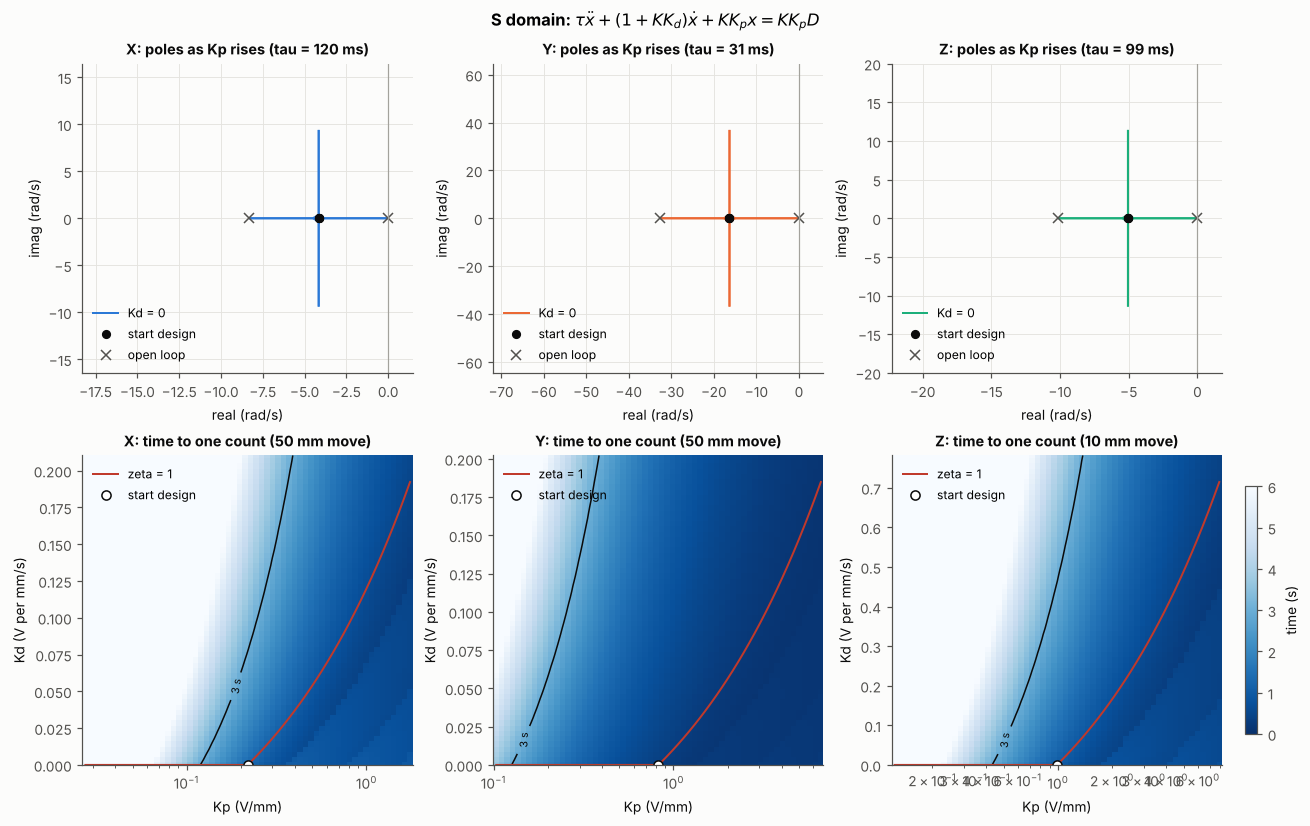

In [6]:
# --- Figure D2: root locus (top) and time to the one-count band (bottom) ---
fig, axs = plt.subplots(2, 3, figsize=(11.8, 7.4), constrained_layout=True)
for j, a in enumerate('XYZ'):
    s = START[a]; K, tau = s['K'], s['tau']
    ax = axs[0, j]
    kps = np.geomspace(s['Kp'] / 40, s['Kp'] * 6, 400)
    for kd, ls, lab in [(0.0, '-', 'Kd = 0')] + ([(s['Kd'], '--', f"Kd = {s['Kd']:.2f} (start)")] if s['Kd'] > 0 else []):
        P = np.array([cl_poles(K, tau, kp, kd) for kp in kps])
        for k in range(2):
            ax.plot(P[:, k].real, P[:, k].imag, ls, color=AXC[a], lw=1.3, label=lab if k == 0 else None)
            ax.plot(P[:, k].real, -P[:, k].imag, ls, color=AXC[a], lw=1.3)
    p0 = cl_poles(K, tau, s['Kp'], s['Kd'])
    ax.plot(p0.real, p0.imag, 'o', color=INK, ms=5, label='start design')
    ax.plot(p0.real, -p0.imag, 'o', color=INK, ms=5)
    ax.plot([-1 / tau, 0], [0, 0], 'x', color=INK_2, ms=7, label='open loop')
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_title(f'{a}: poles as Kp rises (tau = {tau*1e3:.0f} ms)')
    ax.set_xlabel('real (rad/s)'); ax.set_ylabel('imag (rad/s)')
    lim = 2.2 * max(1 / tau, 1 / (2 * tau) * 1.0)
    ax.set_xlim(-lim, 0.08 * lim); ax.set_ylim(-0.9 * lim, 0.9 * lim)
    ax.legend(loc='lower left')
    ax = axs[1, j]
    D = 10.0 if a == 'Z' else 50.0
    kp_g = np.geomspace(s['Kp'] / 8, s['Kp'] * 8, 60)
    kd_g = np.linspace(0, max(s['Kd'] * 3, 0.5 / K * 4), 60)
    KP, KD = np.meshgrid(kp_g, kd_g)
    TS = t_enter_band(K, tau, KP.ravel(), KD.ravel(), SLOT[a] / D).reshape(KP.shape)
    im = ax.pcolormesh(KP, KD, np.clip(TS, 0, 6), cmap='Blues_r', shading='auto', vmin=0, vmax=6)
    cs = ax.contour(KP, KD, TS, levels=[SETTLE_SPEC], colors=[INK], linewidths=1.0)
    ax.clabel(cs, fmt='3 s', fontsize=7)
    kdz = np.maximum((2 * np.sqrt(K * kp_g * tau) - 1) / K, 0)
    ax.plot(kp_g, kdz, color=BAD, lw=1.3, label='zeta = 1')
    ax.plot(s['Kp'], s['Kd'], 'o', color='white', mec=INK, ms=6, label='start design')
    ax.set_xscale('log'); ax.set_ylim(kd_g[0], kd_g[-1])
    ax.set_xlabel('Kp (V/mm)'); ax.set_ylabel('Kd (V per mm/s)')
    ax.set_title(f'{a}: time to one count ({D:.0f} mm move)')
    ax.legend(loc='upper left')
    ax.grid(False)
fig.colorbar(im, ax=axs[1, :], label='time (s)', shrink=0.8, pad=0.02)
fig.suptitle(r'S domain: $\tau\ddot{x}+(1+K K_d)\dot{x}+K K_p x=K K_p D$', fontweight='bold')
save(fig, 'D2_S_domain.png')

**Reading Figure D2.** The loci start on the real axis (overdamped) and meet at $K_p=1/(4\tau K)$ when $K_d=0$; beyond that the poles become complex and the response overshoots, which a one-sided drive cannot correct.
A speed term moves the break-away point to higher $K_p$ and so lets the loop be faster. The blue maps give the linear time to enter the one-count band; the red curve is $\zeta=1$. The
X axis (τ = 120 ms) and Z axis (99 ms) have to rely on $K_d$ for any speed beyond the proportional design; Y (31 ms) is fast enough that the proportional design already settles in a fraction of a second.
**What this analysis leaves out:** the dead band and $V_0$, the saturation and slew limit, the sampled actuation delay, and above all the one-count quantisation with a speed estimate that is stale between pulses.

## 3. Z domain: discretisation at 5 ms with the actuation delay

The firmware runs the law every $T=5$ ms with a zero-order hold on $u$. Because the speed term uses the measured speed (pulse timing) rather than a differenced position, there is **no derivative kick and no
discretisation of a derivative**: the only discretisation is that of the plant and the delay. With state $\xi=[x,\ v,\ u_{k-1},\dots,u_{k-d}]$ for a delay of $d$ samples,

$$\begin{bmatrix}x\\v\end{bmatrix}_{k+1}=\underbrace{\begin{bmatrix}1&\tau(1-a)\\0&a\end{bmatrix}}_{A_d}\begin{bmatrix}x\\v\end{bmatrix}_k+\underbrace{K\begin{bmatrix}T-\tau(1-a)\\1-a\end{bmatrix}}_{B_d}(u_{k-d}-V_{db}),\qquad a=e^{-T/\tau}$$

and $u_k-V_{db}=K_p(D-x_k)-K_d v_k$ in the linear region. The discrete poles are the eigenvalues of the closed-loop matrix. The plant lag pole maps to $a=e^{-T/\tau}$ (0.96 for X, 0.85 for Y, 0.95 for Z at the design τ)
and the integrator to $z=1$. **Stability and delay.** A delay of $d$ samples adds $d$ poles at the origin and moves the others outwards as the loop gets faster, which bounds how far $K_p$ and $K_d$ can be pushed.

In [7]:
T_S = 0.005

def zoh_plant(K, tau, T=T_S):
    a = np.exp(-T / tau)
    Ad = np.array([[1, tau * (1 - a)], [0, a]])
    Bd = K * np.array([T - tau * (1 - a), 1 - a])
    return Ad, Bd

def cl_matrix_z(K, tau, Kp, Kd, d):
    Ad, Bd = zoh_plant(K, tau)
    n = 2 + d
    A = np.zeros((n, n))
    A[:2, :2] = Ad
    # u[k] = -Kp x - Kd v   (regulation about the target, V0 = V_db); applied d samples later
    if d == 0:
        A[:2, :2] = Ad + np.outer(Bd, [-Kp, -Kd])
    else:
        A[:2, 2 + d - 1] = Bd          # oldest stored input drives the plant
        A[2, :2] = [-Kp, -Kd]          # newest input
        for i in range(1, d):
            A[2 + i, 2 + i - 1] = 1.0
    return np.linalg.eigvals(A)

def rho_z(K, tau, Kp, Kd, d):
    return float(np.max(np.abs(cl_matrix_z(K, tau, Kp, Kd, d))))

def corners(a, dsel=None):
    b = BOX[a]
    for K, tau, dl in itertools.product((b['K'][0], b['K'][2]), (b['tau'][0], b['tau'][2]), DELAYS if dsel is None else dsel):
        yield K, tau, int(round(dl / (T_S * 1e3)))

def max_stable_Kp(a, Kd_over_Kp, mult=np.geomspace(0.2, 400, 400)):
    """Largest Kp (V/mm) with all box corners stable at Kd = ratio * Kp (largest first crossing over the corners)."""
    s = START[a]; worst = np.inf
    for K, tau, d in corners(a):
        for m in mult:
            kp = s['Kp'] * m
            if rho_z(K, tau, kp, Kd_over_Kp * kp, d) >= 1.0:
                worst = min(worst, kp); break
    return worst

rows = []
for a in 'XYZ':
    s = START[a]
    for lab, ratio in (('Kd = 0', 0.0), ('Kd/Kp of the start design', s['Kd'] / s['Kp'])):
        rows.append({'axis': a, 'Kd': lab, 'start Kp': s['Kp'], 'Kp at first instability over box and delays (V/mm)': max_stable_Kp(a, ratio)})
display(pd.DataFrame(rows).set_index(['axis', 'Kd']).round(3))

start Kp  Kp at first instability over box and delays (V/mm)
axis Kd                                                                                     
X    Kd = 0                        0.218                                              3.238 
     Kd/Kp of the start design     0.218                                              3.238 
Y    Kd = 0                        0.825                                              2.875 
     Kd/Kp of the start design     0.825                                              2.875 
Z    Kd = 0                        0.988                                             12.103 
     Kd/Kp of the start design     0.988                                             12.103

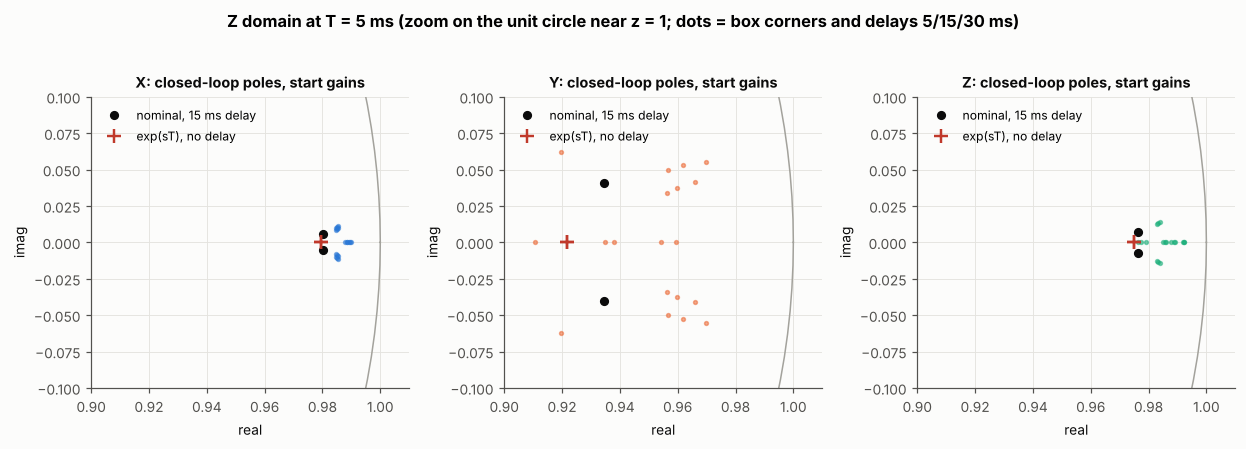

In [8]:
# --- Figure D3: Z-plane poles of the start design over the uncertainty box and delay ---
fig, axs = plt.subplots(1, 3, figsize=(11.4, 3.9))
th = np.linspace(0, 2 * np.pi, 400)
for ax, a in zip(axs, 'XYZ'):
    s = START[a]
    ax.plot(np.cos(th), np.sin(th), color=MUTED, lw=1)
    for K, tau, d in corners(a):
        z = cl_matrix_z(K, tau, s['Kp'], s['Kd'], d)
        z = z[np.abs(z) > 0.3]
        ax.plot(z.real, z.imag, '.', color=AXC[a], alpha=0.55, ms=5)
    Kn, taun = s['K'], s['tau']
    z0 = cl_matrix_z(Kn, taun, s['Kp'], s['Kd'], 3)
    z0 = z0[np.abs(z0) > 0.3]
    ax.plot(z0.real, z0.imag, 'o', color=INK, ms=5, label='nominal, 15 ms delay')
    sp = cl_poles(Kn, taun, s['Kp'], s['Kd'])
    zs = np.exp(sp * T_S)
    ax.plot(zs.real, zs.imag, '+', color=BAD, ms=9, mew=1.6, label='exp(sT), no delay')
    ax.set_xlim(0.9, 1.01); ax.set_ylim(-0.1, 0.1); ax.set_aspect('auto')
    ax.set_title(f'{a}: closed-loop poles, start gains')
    ax.set_xlabel('real'); ax.set_ylabel('imag')
    ax.legend(loc='upper left')
fig.suptitle('Z domain at T = 5 ms (zoom on the unit circle near z = 1; dots = box corners and delays 5/15/30 ms)', y=1.03, fontweight='bold')
fig.tight_layout()
save(fig, 'D3_Z_domain.png')

**Reading the Z-domain check.** At 5 ms the slow poles sit within about 10 % of $z=1$ (3 % for X and Z) (the loop bandwidth is far below the sample rate), so the sampled loop behaves like the continuous one and the
discretisation does not limit the design. The delay, not the sample period, bounds the gains (table above). The sampled delay is a worst case of 30 ms.
What neither the S nor the Z analysis can say is how the **quantised, pulse-timed feedback** behaves: the position changes in steps of one count and the speed is stale between pulses (a pulse every 107 ms at 10 mm/s on X and Y, every 267 ms at 1 mm/s on Z).
That needs the event-based simulation of the next section.

## 4. The firmware law on the plant: event-based simulation

`ctrl_sim.py` simulates the law exactly as the firmware notes describe it, with the plant of Section 1 at 1 ms steps and the controller every 5 ms:

| element | model |
|---|---|
| position feedback | count $N$ (a pulse each $\ell$ mm of travel), $e=D-N\ell$, so $e$ changes in steps of one count; the start lies a random fraction of a count from a pulse edge |
| speed estimate | $\hat v=\ell/\max(T_{tick},\,t-t_{last})$, zero until the first pulse; it decays when a pulse is late |
| law | $u=\mathrm{clamp}(V_0+K_pe-K_d\hat v+n,\,0,\,V_{lim})$, one-sided, slew limit 50 V/s |
| nudge $n$ | grows at 2 V/s once 150 ms pass without a pulse, cleared by the next pulse |
| stop | brake when $e\le\ell$; the carriage then coasts with its own time constant (no extra braking is assumed, which is conservative) |
| plant | $\tau\dot v+v=K(u(t-d)-V_{db})_+$, and from rest only after $u>V_{db}+\Delta V_b$ |

**Assumptions that come from the firmware notes and not from its source:** the 50 V/s slew applies in both directions, the nudge rule above, the stop condition $e\le\ell$, and that braking is no better than coasting.
The source (`05-software`) was not available, so these should be checked against it before the gains are trusted on the bench.

**First look.** The figure compares, for the start design of Section 2 with $V_0=V_{db}$, the linear prediction with the simulation of the real law (nominal plant, 5 ms delay, τ at the design value).

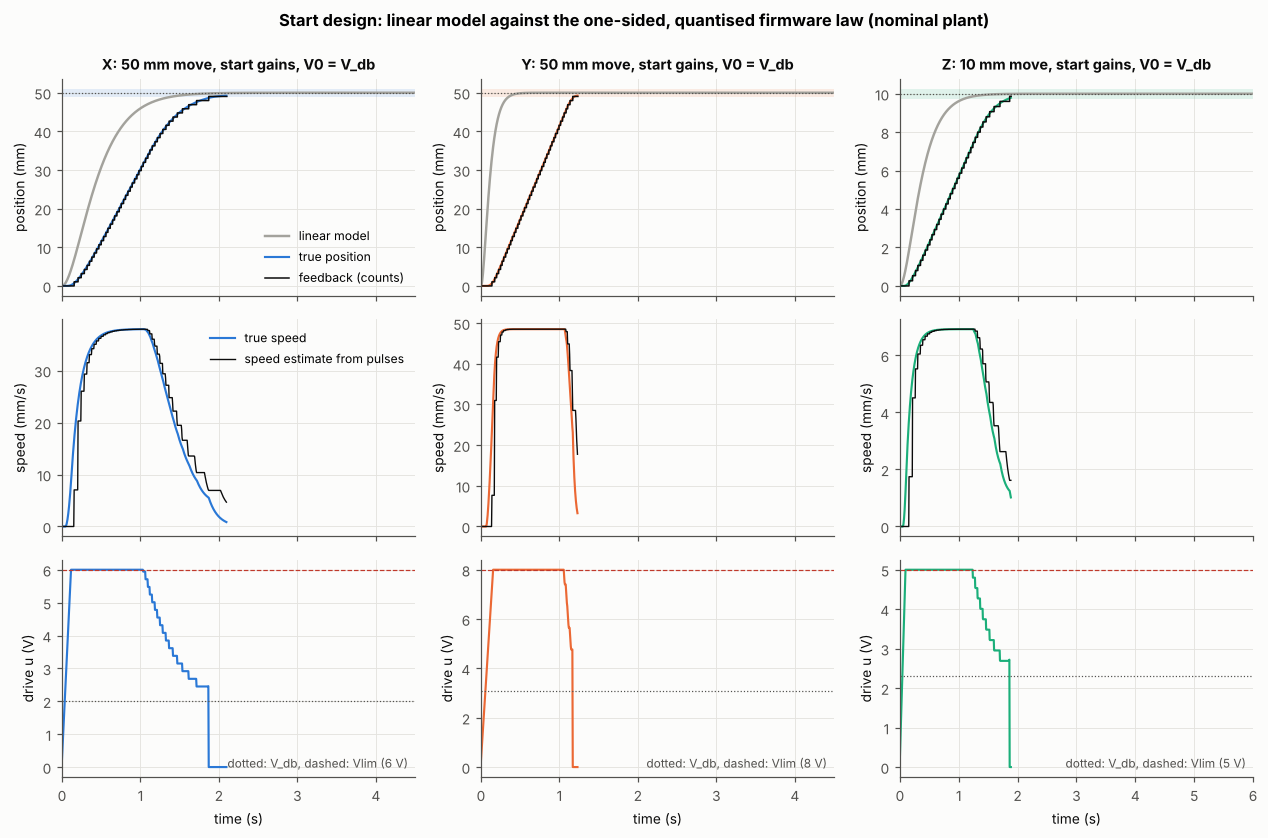

In [9]:
VLIM0 = {'X': 6.0, 'Y': 8.0, 'Z': 5.0}

def trace(a, gains, D, K=None, tau=None, Vdb=None, delay=15.0, dVb=0.3, frac0=0.37, t_max=None, **kw):
    b = BOX[a]
    S = dict(K=np.array([K or b['K'][1]]), tau=np.array([tau or float(ident.loc[a, 'tau_design_ms']) / 1e3]),
             Vdb=np.array([Vdb or b['Vdb'][1]]), delay_ms=np.array([delay]), dVb=np.array([dVb]), frac0=np.array([frac0]),
             D=np.array([float(D)]), D0=np.array([float(D)]), slot=np.array([SLOT[a]]))
    r = run_scen(S, gains, t_max=t_max or (16.0 if a == 'Z' else 8.0), record=1, **kw)
    tr = r['traj']; t = r['t_rec']
    return t, {k: v[0] for k, v in tr.items()}, r

def lin_step(K, tau, Kp, Kd, D, t):
    b = (1 + K * Kd) / tau; c = K * Kp / tau
    p1, p2 = np.roots([1, b, c]).astype(complex)
    if abs(p1 - p2) < 1e-6:
        p2 = p2 - 1e-3
    return D * (1 - np.real((p2 * np.exp(p1 * t) - p1 * np.exp(p2 * t)) / (p2 - p1)))

fig, axs = plt.subplots(3, 3, figsize=(11.6, 7.6), sharex='col')
for j, a in enumerate('XYZ'):
    s = START[a]; D = 10.0 if a == 'Z' else 50.0
    g = (s['Kp'], s['Kd'], BOX[a]['Vdb0'], VLIM0[a])
    t, T, r = trace(a, g, D, K=s['K'], tau=s['tau'], Vdb=BOX[a]['Vdb0'], dVb=0.0, delay=5.0)
    ax = axs[0, j]
    ax.plot(t, lin_step(s['K'], s['tau'], s['Kp'], s['Kd'], D, t), color=MUTED, lw=1.6, label='linear model')
    ax.plot(t, T['x'], color=AXC[a], label='true position')
    ax.step(t, T['n'] * SLOT[a], where='post', color=INK, lw=1.0, label='feedback (counts)')
    ax.axhline(D, color=INK_2, lw=0.8, ls=':'); ax.axhspan(D - SLOT[a], D + SLOT[a], color=AXC[a], alpha=0.12, lw=0)
    ax.set_title(f'{a}: {D:.0f} mm move, start gains, V0 = V_db'); ax.set_ylabel('position (mm)')
    if j == 0:
        ax.legend(loc='lower right')
    ax = axs[1, j]
    ax.plot(t, T['v'], color=AXC[a], label='true speed'); ax.plot(t, T['vhat'], color=INK, lw=0.9, label='speed estimate from pulses')
    ax.set_ylabel('speed (mm/s)')
    if j == 0:
        ax.legend(loc='upper right')
    ax = axs[2, j]
    ax.plot(t, T['u'], color=AXC[a]); ax.axhline(BOX[a]['Vdb0'], color=INK_2, lw=0.8, ls=':'); ax.axhline(VLIM0[a], color=BAD, lw=0.8, ls='--')
    ax.set_ylabel('drive u (V)'); ax.set_xlabel('time (s)')
    note(ax, f"dotted: V_db, dashed: Vlim ({VLIM0[a]:.0f} V)", 'br')
    ax.set_xlim(0, 4.5 if a != 'Z' else 6)
fig.suptitle('Start design: linear model against the one-sided, quantised firmware law (nominal plant)', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D4_linear_vs_firmware.png')

## 5. Gain search over the uncertainty box

$K_p$, $K_d$ and $V_0$ are searched on a grid, with $V_{lim}$ fixed per axis. Each candidate is simulated on a coarse scenario set (K at both edges, τ at three values, $V_{db}$ at three, delay 5 and 30 ms,
both breakaway values, two start phases, moves 3 mm, 10 mm and the design move (50 mm; Z 5 mm): 432 simulations per candidate (Z 288)). The score of a candidate is the **worst** case; a candidate is feasible if no scenario
fails (overshoot ≤ 1.1 mm, within one count, finished before the timeout, settle ≤ 2.7 s on the moves up to the design move, to leave 10 % margin on 3 s) **and** the linear closed loop of Section 3 is stable (largest $|z|$ < 0.999) at every K and τ corner and every delay. Among the feasible candidates, a point is preferred
only if its neighbours on the grid are feasible too (a one-step erosion of the feasible region), and then the fastest one is taken. This keeps the choice away from the edge of a cliff.

* $K_d$ is searched as $c=K\,K_d$ (dimensionless): $c$ = 0 means no speed feedback and $1+c$ is the damping the term adds in $\tau\dot v$.
* $V_0$ is searched as an offset $\delta$ from the identified $V_{db}$.
* $V_{lim}$: Y 8 V, because MECH-09 needs about 38 mm/s, which is $V_{db}+3.9$ V; X 6 V, a compromise between sweep speed (600 mm in about 19 s worst case) and the motor noise that grows above about 5 V; Section 8 shows that the same gains also pass at 5 V (25.5 s for 600 mm) if less noise or less coast is wanted;
  Z 5 V, the highest voltage at which the identified Z law holds (cruise at most 7 mm/s, 200 mm in about 30 s); above 5 V the Z speed is jerky and below the line (Section 8).

In [10]:
GRIDS = {
    'X': dict(Kp=[0.06, 0.09, 0.13, 0.18, 0.25, 0.35, 0.5, 0.7, 1.0], Dd=50),
    'Y': dict(Kp=[0.1, 0.15, 0.22, 0.33, 0.5, 0.75, 1.1, 1.6, 2.4], Dd=50),
    'Z': dict(Kp=[0.35, 0.6, 1.0, 1.7, 2.8, 4.5, 7.0, 10.0], Dd=5),
}
C_GRID = [0.0, 0.15, 0.4, 0.8, 1.5, 3.0]
DV_GRID = [-0.2, 0.0, 0.15, 0.3, 0.5, 0.8, 1.2]
OVER_DESIGN, SETTLE_DESIGN = OVER_SPEC, 0.9 * SETTLE_SPEC

LIN_RHO_MAX = 0.999
_LR = {}
def lin_rho(a, Kp, Kd):
    """Largest closed-loop |z| at T = 5 ms over the K and tau corners of the box and the delays (Section 3)."""
    key = (a, round(float(Kp), 6), round(float(Kd), 6))
    if key not in _LR:
        _LR[key] = max(rho_z(K, tau, Kp, Kd, d) for K, tau, d in corners(a))
    return _LR[key]

def search_axis(a, Vlim, Kps=None, cs=C_GRID, dvs=DV_GRID, Dd=None, chunk=90000, level='coarse', verbose=True):
    g = GRIDS[a]; Kps = g['Kp'] if Kps is None else Kps; Dd = g['Dd'] if Dd is None else Dd
    S = scen_grid(a, tuple(sorted({3, 10, Dd})), level=level)
    ns = len(S['K'])
    cands = np.array(list(itertools.product(Kps, cs, dvs)), float)
    t_max = 14.0 if a == 'Z' else 7.0
    rows = []
    per = max(1, chunk // ns)
    t0 = time.time()
    for i in range(0, len(cands), per):
        C = cands[i:i + per]
        m = len(C)
        SS = {k: np.tile(v, m) for k, v in S.items()}
        Kp = np.repeat(C[:, 0], ns); Kd = np.repeat(C[:, 1], ns) * BOX[a]['Kd_unit']; V0 = BOX[a]['Vdb0'] + np.repeat(C[:, 2], ns)
        r = run_scen(SS, (Kp, Kd, V0, Vlim), t_max=t_max)
        J = judge(a, SS, r, over_lim=OVER_DESIGN, settle_lim=SETTLE_DESIGN)
        J['cand'] = np.repeat(np.arange(i, i + m), ns)
        J['fail'] = ~(J.ok_done & J.ok_over & J.ok_band & J.ok_time)
        for ci, grp in J.groupby('cand'):
            dd = grp[grp.D0 == Dd]
            rows.append(dict(cand=ci, t_worst=dd.t_rest.max(), t_p90=dd.t_rest.quantile(0.9), over_worst=grp.over_fb.max(),
                             n_fail=int(grp.fail.sum()), n_late=int((~grp.ok_time).sum()), n_over=int((~grp.ok_over).sum()),
                             n_band=int((~grp.ok_band).sum()), n_done=int((~grp.ok_done).sum())))
    R = pd.DataFrame(rows).set_index('cand')
    R[['Kp', 'c', 'dv']] = cands[R.index]
    R['Kd'] = R.c * BOX[a]['Kd_unit']; R['V0'] = BOX[a]['Vdb0'] + R.dv; R['Vlim'] = Vlim
    # linear stability over the box and delays is a hard condition (a candidate that is unstable at a corner is not feasible, whatever the simulation of the stop rule shows)
    R['lin_rho'] = [lin_rho(a, kp, kd) for kp, kd in zip(R.Kp, R.Kd)]
    R['n_fail_sim'] = R['n_fail']
    R['n_fail'] = R['n_fail'] + np.where(R['lin_rho'] >= LIN_RHO_MAX, 1000, 0)
    if verbose:
        print(f'{a}: {len(cands)} candidates x {ns} scenarios in {time.time()-t0:.0f} s, feasible {int((R.n_fail==0).sum())}')
    return R, (list(Kps), list(cs), list(dvs))

def pick(R, axes_vals):
    Kps, cs, dvs = axes_vals
    F = np.zeros((len(Kps), len(cs), len(dvs)), bool); T = np.full(F.shape, np.inf)
    for _, r in R.iterrows():
        i = int(np.argmin(np.abs(np.array(Kps) - r.Kp))); j = int(np.argmin(np.abs(np.array(cs) - r.c))); k = int(np.argmin(np.abs(np.array(dvs) - r.dv)))
        F[i, j, k] = r.n_fail == 0; T[i, j, k] = r.t_worst
    E = minimum_filter(F.astype(int), size=3, mode='constant', cval=0).astype(bool) & F
    use = E if E.any() else F
    if not use.any():
        return None, F, T, E
    idx = np.unravel_index(np.argmin(np.where(use, T, np.inf)), F.shape)
    return idx, F, T, E

def best_row(R):
    return R.sort_values(['n_fail', 't_worst']).iloc[0]

def refine_grid(a, row):
    kp = row.Kp * np.array([0.7, 0.85, 1.0, 1.2, 1.45])
    c = np.unique(np.round(np.clip(row.c + np.array([-0.2, -0.1, 0.0, 0.1, 0.2, 0.4]) * max(1.0, row.c), 0, None), 3))
    dv = row.dv + np.array([-0.15, -0.075, 0.0, 0.075, 0.15])
    return list(kp), list(c), list(dv)

def ranked(R, av):
    """Feasible rows of R ordered by (neighbours also feasible first, then worst settle)."""
    Kps, cs, dvs = av
    F = np.zeros((len(Kps), len(cs), len(dvs)), bool); pos = {}
    for ci, r in R.iterrows():
        i = int(np.argmin(np.abs(np.array(Kps) - r.Kp))); j = int(np.argmin(np.abs(np.array(cs) - r.c))); k = int(np.argmin(np.abs(np.array(dvs) - r.dv)))
        F[i, j, k] = r.n_fail == 0; pos[ci] = (i, j, k)
    E = minimum_filter(F.astype(int), size=3, mode='constant', cval=0).astype(bool) & F
    rows = [(0 if E[pos[ci]] else 1, r.t_worst, ci) for ci, r in R.iterrows() if r.n_fail == 0]
    return [R.loc[ci] for _, _, ci in sorted(rows)]

def full_fails(a, row):
    """Failing plants of the FULL grid (all move lengths of the requirement) for the rounded gains of a search row."""
    g = dict(Kp=round(float(row.Kp), 3), Kd=round(float(row.Kd), 3), Vlim=float(row.Vlim), V0=round(float(row.V0), 2))
    S = scen_grid(a, tuple(MOVES_SPEC[a]), level='full', seed=1)
    r = run_scen(S, (g['Kp'], g['Kd'], g['V0'], g['Vlim']), t_max=(16.0 if a == 'Z' else 8.0))
    J = judge(a, S, r, over_lim=OVER_SPEC, settle_lim=SETTLE_SPEC)
    return int((~(J.ok_done & J.ok_over & J.ok_band & J.ok_time)).sum())

USE_CACHE = False          # development switch: reuse results_controllers/search_cache.pkl instead of searching again
import pickle
CACHE = RES / 'search_cache.pkl'
SEARCH = {}
if USE_CACHE and CACHE.exists():
    SEARCH = pickle.load(open(CACHE, 'rb'))
else:
    for a in 'XYZ':
        R0, av0 = search_axis(a, VLIM0[a])
        idx0, F0, T0, E0 = pick(R0, av0)
        seed_row = R0.loc[R0.index[0]] if False else None
        if idx0 is not None:
            seed_row = R0[(np.isclose(R0.Kp, av0[0][idx0[0]])) & (np.isclose(R0.c, av0[1][idx0[1]])) & (np.isclose(R0.dv, av0[2][idx0[2]]))].iloc[0]
        else:
            seed_row = best_row(R0)
        kps, cs_, dvs_ = refine_grid(a, seed_row)
        R1, av1 = search_axis(a, VLIM0[a], Kps=kps, cs=cs_, dvs=dvs_)
        pool = ranked(R1, av1)
        stage, flagged, row, nfull = 'refined', False, None, None
        best = (10 ** 9, None)
        for cand in pool[:15]:
            nf_ = full_fails(a, cand)
            if nf_ < best[0]:
                best = (nf_, cand)
            if nf_ == 0:
                break
        if pool and best[0] == 0:
            row, nfull = best[1], 0
        elif pool:
            row, nfull, flagged, stage = best[1], best[0], True, 'best available (full grid not clean)'
        else:
            row, flagged, stage = best_row(R1), True, 'best available (no feasible candidate)'
        SEARCH[a] = dict(R0=R0, av0=av0, idx0=idx0, F0=F0, T0=T0, R1=R1, av1=av1, row=row, flagged=flagged, stage=stage, n_pool=len(pool))
    pickle.dump(SEARCH, open(CACHE, 'wb'))
for a in 'XYZ':
    row = SEARCH[a]['row']
    print(f"{a} [{SEARCH[a]['stage']}]: Kp {row.Kp:.3g}  c {row.c:.3g}  dV0 {row.dv:.3g}  worst settle {row.t_worst:.2f} s  failing scenarios {int(row.n_fail)} of 432  flagged={SEARCH[a]['flagged']}")

X: 378 candidates x 432 scenarios in 90 s, feasible 0


X: 150 candidates x 432 scenarios in 21 s, feasible 12


Y: 378 candidates x 432 scenarios in 74 s, feasible 57


Y: 150 candidates x 432 scenarios in 12 s, feasible 79


Z: 336 candidates x 432 scenarios in 120 s, feasible 9


Z: 150 candidates x 432 scenarios in 23 s, feasible 96


X [refined]: Kp 0.35  c 0.5  dV0 0.45  worst settle 2.55 s  failing scenarios 0 of 432  flagged=False
Y [refined]: Kp 0.637  c 0.5  dV0 0.875  worst settle 1.85 s  failing scenarios 0 of 432  flagged=False
Z [refined]: Kp 1.7  c 1  dV0 0.8  worst settle 2.16 s  failing scenarios 0 of 432  flagged=False


### Search maps and the chosen gains

Figure D5 shows the coarse search for each axis as the number of failing scenarios (of 432) on the $K_p$-$c$ plane (best $V_0$ offset at each point) and on the $K_p$-$V_0$ plane (best $c$). Pale = few or no failures.
X has no fully clean point on the coarse grid (Z has a few); the refined grid around the best point (circle) removes the last failures.

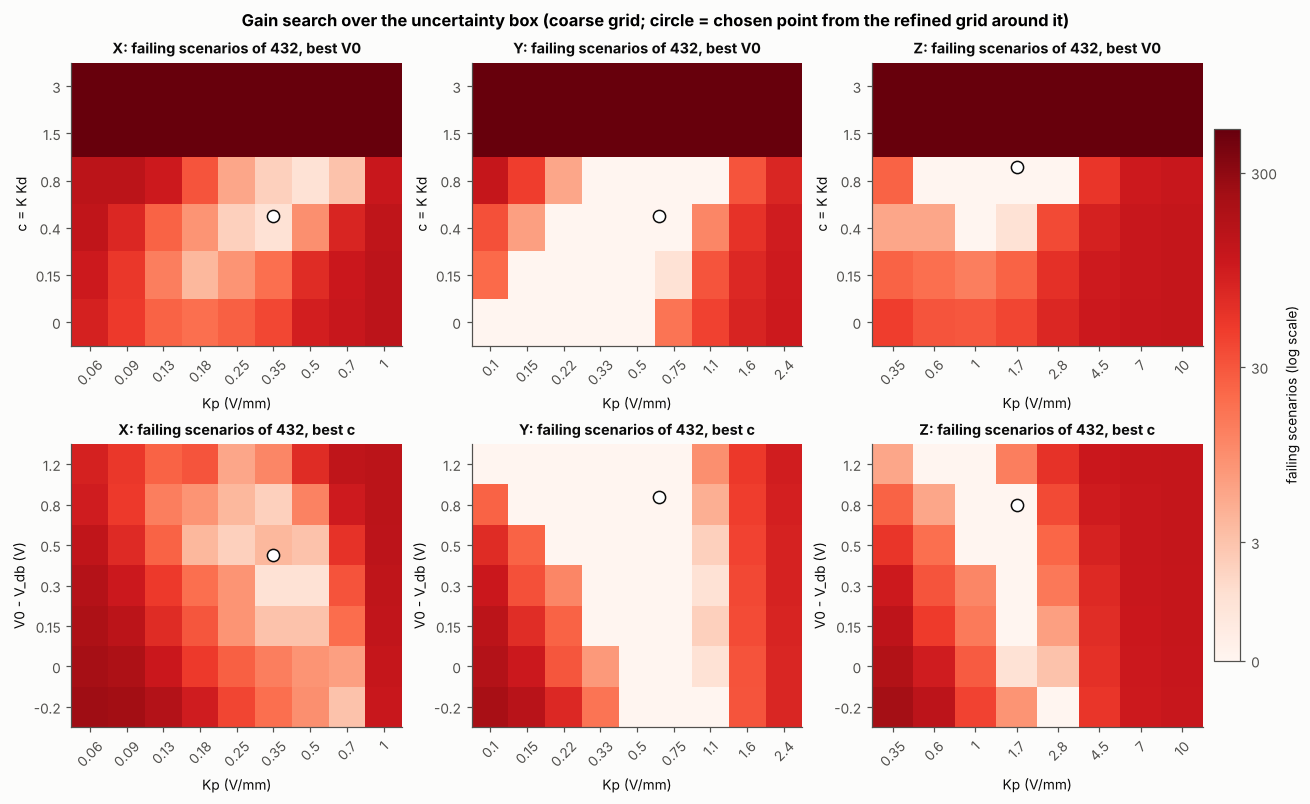

,Kp (V/mm),Kd (V per mm/s),Vlim (V),V0 (V),V0 - V_db (V),c = K Kd,search worst settle (s),stage,flagged
axis,,,,,,,,,
X,0.350,0.053,6.0,2.46,0.45,0.5,2.55,refined,False
Y,0.637,0.051,8.0,3.97,0.88,0.5,1.85,refined,False
Z,1.700,0.391,5.0,3.10,0.80,1.0,2.16,refined,False


Firmware format `[Kp, Kd, Vlim, V0]`:

```
gain_x = [0.35, 0.053, 6, 2.46]
gain_y = [0.637, 0.051, 8, 3.97]
gain_z = [1.7, 0.391, 5, 3.1]
```

In [11]:
def row_to_gains(a, row):
    return dict(Kp=round(float(row.Kp), 3), Kd=round(float(row.Kd), 3), Vlim=float(row.Vlim), V0=round(float(row.V0), 2))

GAINS = {a: row_to_gains(a, SEARCH[a]['row']) for a in 'XYZ'}

def G(a, g=None):
    g = g or GAINS[a]
    return (g['Kp'], g['Kd'], g['V0'], g['Vlim'])

fig, axs = plt.subplots(2, 3, figsize=(11.8, 7.2), constrained_layout=True)
for j, a in enumerate('XYZ'):
    Sx = SEARCH[a]; R = Sx['R0']; Kps, cs, dvs = Sx['av0']
    nf = np.full((len(Kps), len(cs), len(dvs)), np.nan)
    for _, r in R.iterrows():
        i = int(np.argmin(np.abs(np.array(Kps) - r.Kp))); jj = int(np.argmin(np.abs(np.array(cs) - r.c))); k = int(np.argmin(np.abs(np.array(dvs) - r.dv)))
        nf[i, jj, k] = r.n_fail
    row = Sx['row']
    xi = np.interp(np.log(row.Kp), np.log(Kps), range(len(Kps)))
    for r_i, (axis_red, ylab, yv, yc) in enumerate(((2, 'c = K Kd', cs, row.c), (1, 'V0 - V_db (V)', dvs, row.dv))):
        ax = axs[r_i, j]
        N2 = np.nanmin(nf, axis=axis_red)                      # fewest failing scenarios over the other parameter
        im2 = ax.imshow(np.log10(N2.T + 1), origin='lower', aspect='auto', cmap='Reds', vmin=0, vmax=2.7)
        ax.set_xticks(range(len(Kps))); ax.set_xticklabels([f'{k:g}' for k in Kps], rotation=45)
        ax.set_yticks(range(len(yv))); ax.set_yticklabels([f'{d:g}' for d in yv])
        ax.set_xlabel('Kp (V/mm)'); ax.set_ylabel(ylab); ax.grid(False)
        ax.set_title(f"{a}: failing scenarios of 432, best {'V0' if r_i == 0 else 'c'}")
        yi = np.interp(yc, yv, range(len(yv)))
        ax.plot(xi, yi, 'o', mfc='white', mec=INK, ms=8)
cb = fig.colorbar(im2, ax=axs, shrink=0.8, pad=0.01, label='failing scenarios (log scale)')
cb.set_ticks(np.log10(np.array([0, 3, 30, 300]) + 1)); cb.set_ticklabels(['0', '3', '30', '300'])
fig.suptitle('Gain search over the uncertainty box (coarse grid; circle = chosen point from the refined grid around it)', fontweight='bold')
save(fig, 'D5_gain_search.png')

gain_rows = []
for a in 'XYZ':
    g = GAINS[a]
    gain_rows.append({'axis': a, 'Kp (V/mm)': g['Kp'], 'Kd (V per mm/s)': g['Kd'], 'Vlim (V)': g['Vlim'], 'V0 (V)': g['V0'],
                      'V0 - V_db (V)': round(g['V0'] - BOX[a]['Vdb0'], 2), 'c = K Kd': round(g['Kd'] * float(ident.loc[a, 'K_mm_s_per_V']), 2),
                      'search worst settle (s)': round(float(SEARCH[a]['row'].t_worst), 2), 'stage': SEARCH[a]['stage'], 'flagged': SEARCH[a]['flagged']})
display(pd.DataFrame(gain_rows).set_index('axis'))
display(Markdown('Firmware format `[Kp, Kd, Vlim, V0]`:\n\n```\n' + '\n'.join(f"gain_{a.lower()} = [{GAINS[a]['Kp']:g}, {GAINS[a]['Kd']:g}, {GAINS[a]['Vlim']:g}, {GAINS[a]['V0']:g}]" for a in 'XYZ') + '\n```'))

## 6. Verification on the full uncertainty grid

The chosen (rounded) gains are now run on the **full** grid: K, τ and $V_{db}$ at three values each (the edges and the nominal), delay 5, 15 and 30 ms, both breakaway values and three start phases, which is 486 plants per move, for every move length of the requirement.
Pass criteria are the requirements themselves, with no design margin: settle ≤ 3 s, finish before the timeout, at most one count short, overshoot ≤ 1.1 mm of feedback position.

In [12]:
def verify(a, moves, level='full', gains=None, t_max=None, mod=None, seed=1, record=0, **kw):
    S = scen_grid(a, moves, level=level, seed=seed)
    if mod is not None:
        S = mod(S)
    tm = t_max or (16.0 if a == 'Z' else 8.0)
    r = run_scen(S, G(a, gains), t_max=tm, record=record, **kw)
    J = judge(a, S, r, over_lim=OVER_SPEC, settle_lim=SETTLE_SPEC)
    for k in ('K', 'tau', 'Vdb', 'delay_ms', 'dVb', 'frac0'):
        J[k] = S[k]
    J['axis'] = a
    J['fail'] = ~(J.ok_done & J.ok_over & J.ok_band & J.ok_time)
    return S, r, J

def summarise(J, a):
    slot = SLOT[a]
    g = J.groupby('D0')
    out = pd.DataFrame({
        'plants': g.size(),
        'worst settle (s)': g.t_rest.max(), 'p95 settle (s)': g.t_rest.quantile(0.95), 'median settle (s)': g.t_rest.median(),
        'worst overshoot (mm)': g.over_fb.max(),
        'worst short of target (counts)': g.err_fb.max() / slot,
        'settle > 3 s': g.apply(lambda d: int((d.t_rest > SETTLE_SPEC).sum())),
        'overshoot > 1.1 mm': g.apply(lambda d: int((~d.ok_over).sum())),
        'outside one count': g.apply(lambda d: int((~d.ok_band).sum())),
        'not finished': g.apply(lambda d: int((~d.ok_done).sum())),
    })
    out.index.name = 'move (mm)'
    return out

VER, VERJ = {}, {}
for a in 'XYZ':
    S, r, J = verify(a, MOVES_SPEC[a])
    VERJ[a] = J; VER[a] = summarise(J, a)
    display(Markdown(f'**{a} axis**, gains `[{GAINS[a]["Kp"]:g}, {GAINS[a]["Kd"]:g}, {GAINS[a]["Vlim"]:g}, {GAINS[a]["V0"]:g}]`'))
    display(VER[a].round(2))

**X axis**, gains `[0.35, 0.053, 6, 2.46]`

,plants,worst settle (s),p95 settle (s),median settle (s),worst overshoot (mm),worst short of target (counts),settle > 3 s,overshoot > 1.1 mm,outside one count,not finished
move (mm),,,,,,,,,,
3.0,486,0.90,0.84,0.52,1.05,0.99,0,0,0,0
10.0,486,1.33,1.21,0.96,1.05,1.00,0,0,0,0
25.0,486,1.84,1.69,1.42,1.06,0.99,0,0,0,0
50.0,486,2.53,2.41,2.09,1.03,1.00,0,0,0,0


**Y axis**, gains `[0.637, 0.051, 8, 3.97]`

,plants,worst settle (s),p95 settle (s),median settle (s),worst overshoot (mm),worst short of target (counts),settle > 3 s,overshoot > 1.1 mm,outside one count,not finished
move (mm),,,,,,,,,,
3.0,486,0.44,0.41,0.30,1.05,0.99,0,0,0,0
10.0,486,0.76,0.69,0.56,0.24,1.00,0,0,0,0
25.0,486,1.20,1.09,0.88,0.00,0.99,0,0,0,0
50.0,486,1.85,1.78,1.40,0.00,1.00,0,0,0,0


**Z axis**, gains `[1.7, 0.391, 5, 3.1]`

,plants,worst settle (s),p95 settle (s),median settle (s),worst overshoot (mm),worst short of target (counts),settle > 3 s,overshoot > 1.1 mm,outside one count,not finished
move (mm),,,,,,,,,,
3.0,486,1.64,1.40,0.99,0.26,1.00,0,0,0,0
5.0,486,2.18,2.03,1.35,0.25,1.00,0,0,0,0
10.0,486,3.64,3.44,2.17,0.26,0.99,67,0,0,0
25.0,486,7.98,7.84,4.67,0.27,1.00,486,0,0,0
50.0,486,15.26,15.12,8.75,0.27,1.00,486,0,0,0


**Z axis, CTRL-04.** The requirement asks every axis to settle within 3 s for moves up to 50 mm. On Z that cannot be met by any gains: at 5 V the identified Z moves at most $K(V_{lim}-V_{db})$ = 6.9 mm/s,
so 50 mm takes 7.3 s before any deceleration. The Z column above therefore reports 3.0 s as a requirement only for the shorter moves listed in `TIME_D` (5 mm); the settle-versus-distance curve (Figure D8) gives the distance that fits in 3 s.

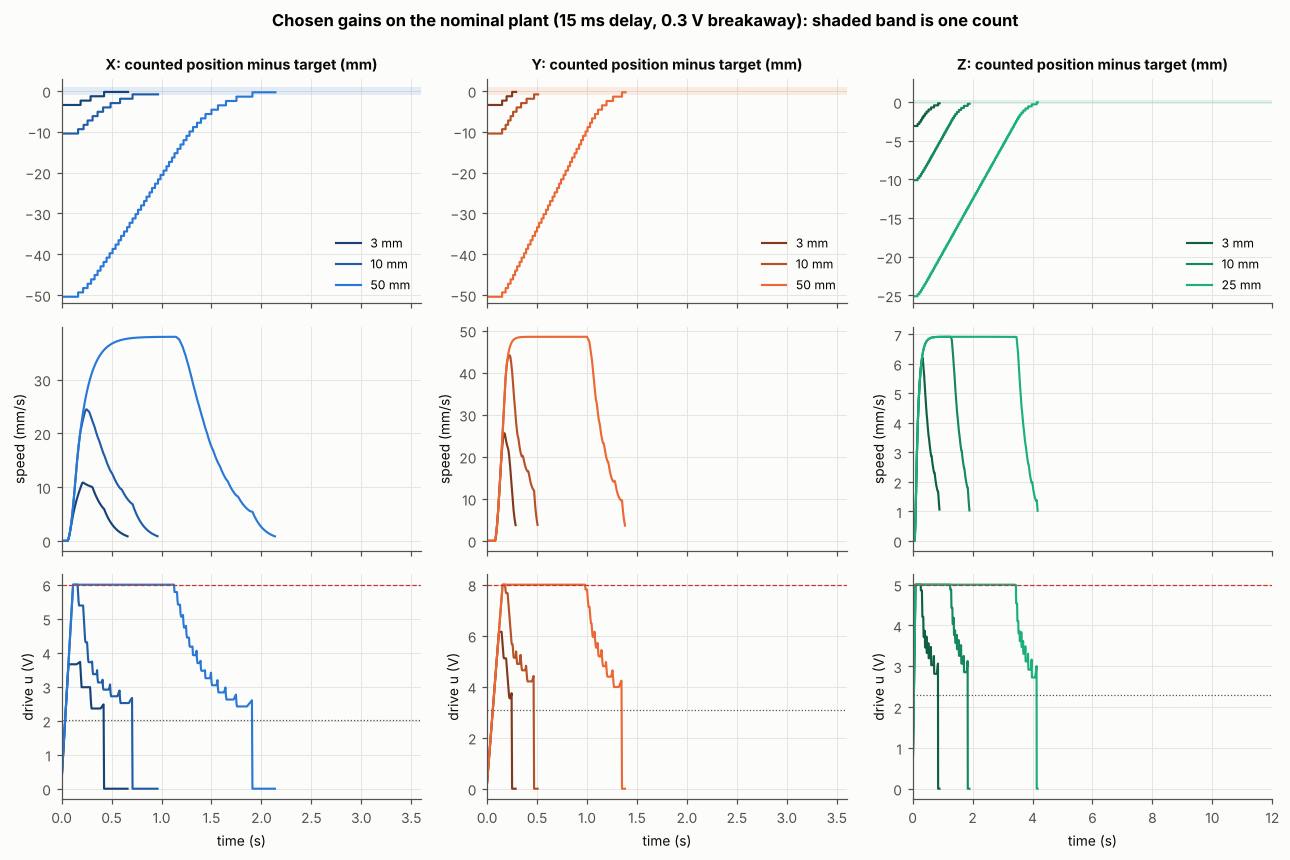

In [13]:
# --- Figure D6: nominal step responses of each axis for several move lengths ---
shades = {0: 0.95, 1: 0.65, 2: 0.4}
fig, axs = plt.subplots(3, 3, figsize=(11.8, 7.8), sharex='col')
for j, a in enumerate('XYZ'):
    moves = [3, 10, 50] if a != 'Z' else [3, 10, 25]
    for m_i, D in enumerate(moves):
        col = mpl.colors.to_rgb(AXC[a]); col = tuple(1 - (1 - c) * shades[m_i] for c in col) if False else tuple(np.array(col) * (0.55 + 0.45 * m_i / 2))
        t, T, r = trace(a, G(a), D + 0.4 * SLOT[a], dVb=0.3, delay=15.0, t_max=(16.0 if a == 'Z' else 6.0))
        tr_end = r['t_rest'][0] + 0.6
        axs[0, j].step(t, T['n'] * SLOT[a] - (D + 0.4 * SLOT[a]), where='post', color=col, label=f'{D} mm')
        axs[1, j].plot(t, T['v'], color=col)
        axs[2, j].plot(t, T['u'], color=col)
    axs[0, j].axhspan(-SLOT[a], SLOT[a], color=AXC[a], alpha=0.12, lw=0)
    axs[0, j].set_ylim(-(max(moves) + 2) if a != 'Z' else -(max(moves) + 1), 3)
    axs[0, j].set_title(f"{a}: counted position minus target (mm)")
    axs[0, j].legend(loc='lower right')
    axs[1, j].set_ylabel('speed (mm/s)')
    axs[2, j].set_ylabel('drive u (V)'); axs[2, j].set_xlabel('time (s)')
    axs[2, j].axhline(BOX[a]['Vdb0'], color=INK_2, lw=0.8, ls=':'); axs[2, j].axhline(GAINS[a]['Vlim'], color=BAD, lw=0.8, ls='--')
    axs[2, j].set_xlim(0, 3.6 if a != 'Z' else 12)
fig.suptitle('Chosen gains on the nominal plant (15 ms delay, 0.3 V breakaway): shaded band is one count', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D6_nominal_moves.png')

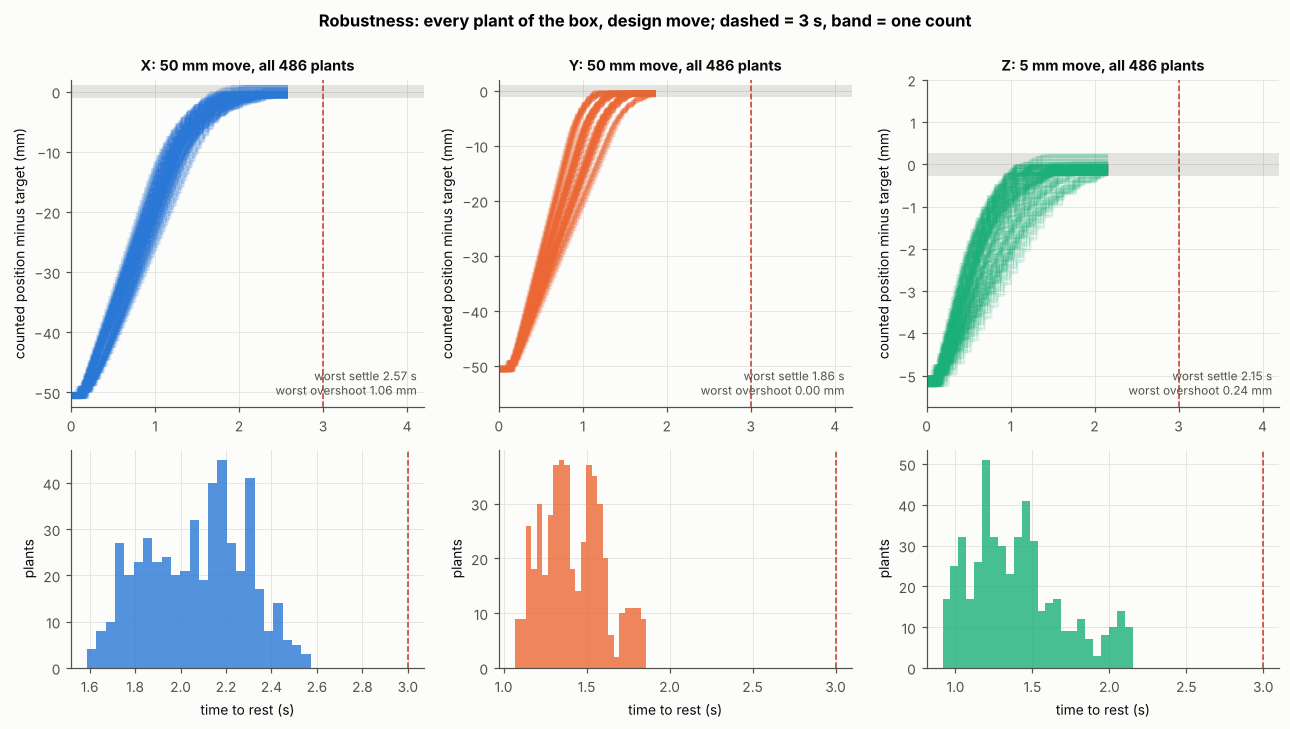

In [14]:
# --- Figure D7: the whole uncertainty box at once (design move) ---
fig, axs = plt.subplots(2, 3, figsize=(11.8, 6.6), gridspec_kw={'height_ratios': [1.5, 1]})
for j, a in enumerate('XYZ'):
    Dd = TIME_D[a]
    S, r, J = verify(a, (Dd,), record=486)
    tr = r['traj']; t = r['t_rec']
    ax = axs[0, j]
    err = tr['n'] * SLOT[a] - S['D'][:486, None]
    for k in range(len(J)):
        ax.step(t, err[k], where='post', color=AXC[a], alpha=0.10, lw=0.7)
    ax.axhspan(-SLOT[a], SLOT[a], color=INK, alpha=0.10, lw=0)
    ax.axvline(SETTLE_SPEC, color=BAD, lw=1.0, ls='--')
    ax.set_xlim(0, 4.2); ax.set_ylim(-1.15 * Dd if a != 'X' else -Dd * 1.05, 2.0)
    ax.set_title(f'{a}: {Dd:.0f} mm move, all {len(J)} plants'); ax.set_ylabel('counted position minus target (mm)')
    note(ax, f"worst settle {J.t_rest.max():.2f} s\nworst overshoot {J.over_fb.max():.2f} mm", 'br')
    ax = axs[1, j]
    ax.hist(J.t_rest, bins=24, color=AXC[a], alpha=0.8)
    ax.axvline(SETTLE_SPEC, color=BAD, lw=1.0, ls='--')
    ax.set_xlabel('time to rest (s)'); ax.set_ylabel('plants')
fig.suptitle('Robustness: every plant of the box, design move; dashed = 3 s, band = one count', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D7_box_responses.png')

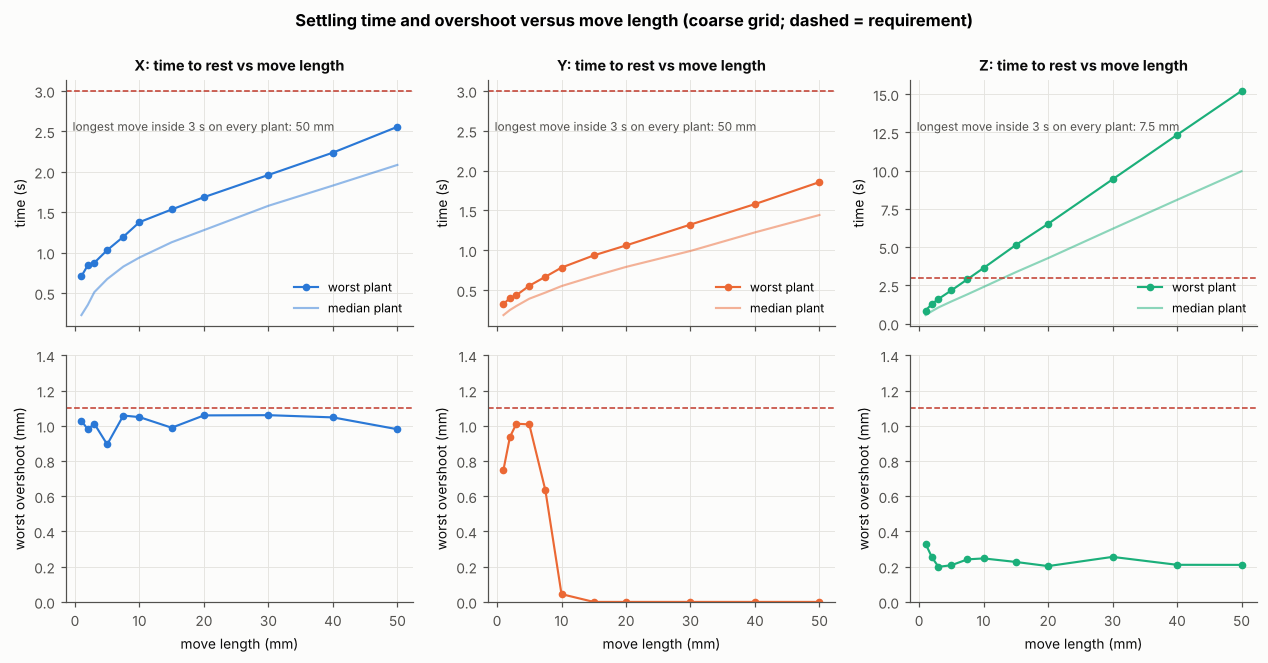

,X,Y,Z
longest move inside 3 s (mm),50.0,50.0,7.5


In [15]:
# --- Figure D8: settle time and overshoot against move length ---
dists = [1, 2, 3, 5, 7.5, 10, 15, 20, 30, 40, 50]
CURVE = {}
for a in 'XYZ':
    rows = []
    S, r, J = verify(a, tuple(dists), level='coarse', t_max=(24.0 if a == 'Z' else 8.0))
    g = J.groupby('D0')
    CURVE[a] = pd.DataFrame({'worst': g.t_rest.max(), 'median': g.t_rest.median(), 'over': g.over_fb.max(), 'short': g.err_fb.max() / SLOT[a]})
fig, axs = plt.subplots(2, 3, figsize=(11.6, 6.0), sharex='col')
for j, a in enumerate('XYZ'):
    c = CURVE[a]
    ax = axs[0, j]
    ax.plot(c.index, c.worst.replace(np.inf, np.nan), '-o', color=AXC[a], ms=4, label='worst plant')
    ax.plot(c.index, c['median'], '-', color=AXC[a], alpha=0.5, label='median plant')
    ax.axhline(SETTLE_SPEC, color=BAD, lw=1.0, ls='--')
    ok = c.worst[c.worst <= SETTLE_SPEC]
    Dmax = ok.index.max() if len(ok) else np.nan
    ax.set_title(f'{a}: time to rest vs move length'); ax.set_ylabel('time (s)')
    ax.text(0.02, 0.84, f'longest move inside 3 s on every plant: {Dmax:g} mm', transform=ax.transAxes, color=INK_2, fontsize=7.8, va='top')
    ax.legend(loc='lower right')
    ax = axs[1, j]
    ax.plot(c.index, c.over, '-o', color=AXC[a], ms=4)
    ax.axhline(OVER_SPEC, color=BAD, lw=1.0, ls='--')
    ax.set_xlabel('move length (mm)'); ax.set_ylabel('worst overshoot (mm)'); ax.set_ylim(0, 1.4)
fig.suptitle('Settling time and overshoot versus move length (coarse grid; dashed = requirement)', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D8_move_length.png')
DMAX = {a: (CURVE[a].worst[CURVE[a].worst <= SETTLE_SPEC].index.max() if (CURVE[a].worst <= SETTLE_SPEC).any() else np.nan) for a in 'XYZ'}
display(pd.DataFrame({'longest move inside 3 s (mm)': DMAX}).T)

## 7. Long moves, timeout and limits (MECH-09, CTRL-08)

* **MECH-09:** the Y axis must traverse 1 m in 30 s. The whole box is simulated for 1000 mm.
* **CTRL-08 timeout:** the move must finish inside 15 s + distance / 3 mm/s (Z: / 1 mm/s). The ratio of the time to rest and the timeout is reported for every plant.
* **CTRL-08 soft limits:** the target is held 5 mm inside the end; the overshoot must stay inside that 5 mm. If a limit switch closes at cruise speed the drive is cut and the axis coasts: the free-coast distance is $K(V_{lim}-V_{db})\,\tau$.

,move (mm),median time (s),worst time (s),best time (s),timeout (s),worst time / timeout,"cruise speed, worst (mm/s)","cruise speed, best (mm/s)",free coast at best-plant cruise (mm),overshoot worst (mm)
axis,,,,,,,,,,
X,600.0,16.61,19.05,14.43,215.00,0.09,33.45,42.88,6.81,1.06
Y,1000.0,21.71,27.79,16.77,348.33,0.08,36.63,60.54,3.25,0.00
Z,200.0,38.40,58.81,24.56,215.00,0.27,3.44,8.24,1.17,0.26


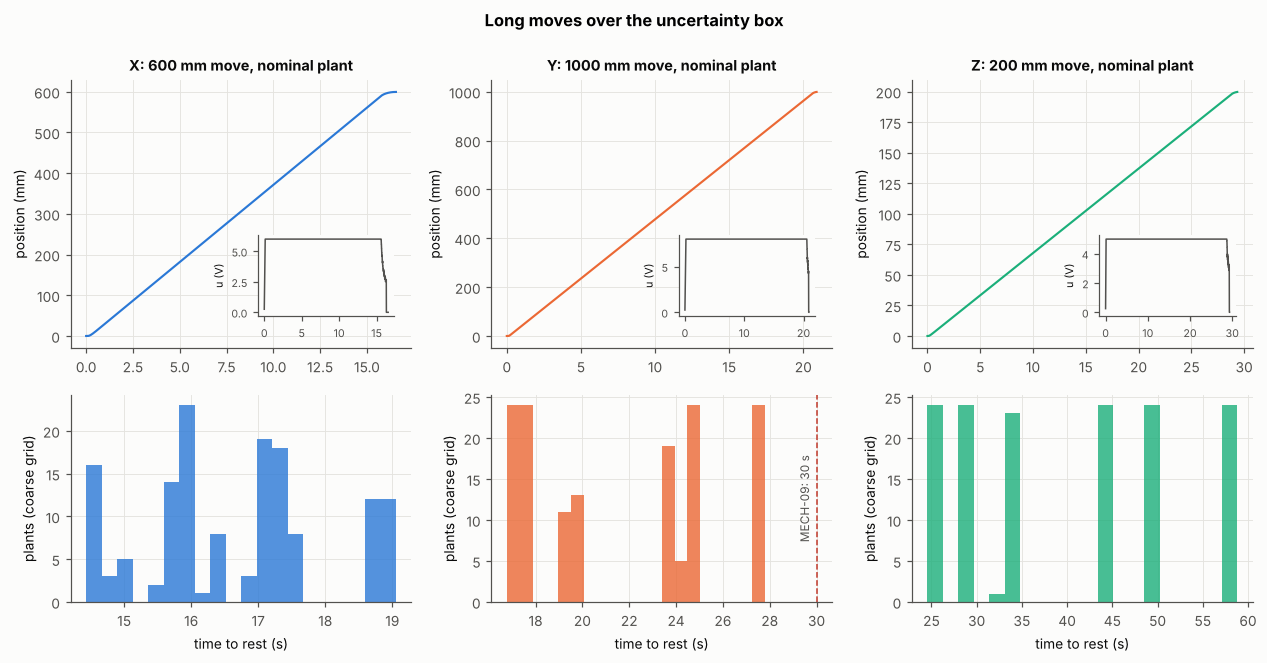

In [16]:
LONG = {'X': 600.0, 'Y': 1000.0, 'Z': 200.0}
rows = []; LONGJ = {}
for a in 'XYZ':
    S, r, J = verify(a, (LONG[a],), level='coarse', t_max={'X': 60.0, 'Y': 60.0, 'Z': 120.0}[a])
    LONGJ[a] = J
    to = timeout_s(a, LONG[a])
    b = BOX[a]; g = GAINS[a]
    v_cruise = b['K'][2] * (g['Vlim'] - b['Vdb'][0])
    coast = v_cruise * b['tau'][2]
    rows.append({'axis': a, 'move (mm)': LONG[a], 'median time (s)': J.t_rest.median(), 'worst time (s)': J.t_rest.max(), 'best time (s)': J.t_rest.min(),
                 'timeout (s)': to, 'worst time / timeout': J.t_rest.max() / to,
                 'cruise speed, worst (mm/s)': b['K'][0] * (g['Vlim'] - b['Vdb'][2]), 'cruise speed, best (mm/s)': v_cruise,
                 'free coast at best-plant cruise (mm)': coast, 'overshoot worst (mm)': J.over_fb.max()})
LONGT = pd.DataFrame(rows).set_index('axis')
display(LONGT.round(2))

fig, axs = plt.subplots(2, 3, figsize=(11.6, 6.0), gridspec_kw={'height_ratios': [1.3, 1]})
for j, a in enumerate('XYZ'):
    J = LONGJ[a]
    t, T, r = trace(a, G(a), LONG[a], dVb=0.3, delay=15.0, t_max={'X': 40.0, 'Y': 40.0, 'Z': 60.0}[a])
    ax = axs[0, j]
    ax.plot(t, T['x'], color=AXC[a])
    ax.set_title(f'{a}: {LONG[a]:.0f} mm move, nominal plant'); ax.set_ylabel('position (mm)')
    ax2 = ax.inset_axes([0.55, 0.12, 0.4, 0.3])
    ax2.plot(t, T['u'], color=INK_2, lw=1.0); ax2.set_ylabel('u (V)', fontsize=7); ax2.tick_params(labelsize=7); ax2.grid(False)
    ax = axs[1, j]
    ax.hist(J.t_rest, bins=20, color=AXC[a], alpha=0.8)
    ax.set_xlabel('time to rest (s)'); ax.set_ylabel('plants (coarse grid)')
    if a == 'Y':
        ax.axvline(T_TRAV, color=BAD, lw=1.0, ls='--'); ax.text(T_TRAV - 0.2, 0.5, 'MECH-09: 30 s', transform=ax.get_xaxis_transform(), rotation=90, ha='right', va='center', color=INK_2, fontsize=7.8)
fig.suptitle('Long moves over the uncertainty box', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D9_long_moves.png')

## 8. Beyond the box: stress tests and the Vlim choice

The box of Section 1 is where the controller is *guaranteed* to meet the requirements. The next table pushes each assumption beyond its edge, one at a time, to see how much room is left. A failing plant here is not a defect of the design;
it marks the quantity that a bench identification would need to bound.

plants  failing  worst settle (s)  not finished  worst overshoot (mm)  outside one count  late (> 3 s)
axis case                                                                                                                          
X    reference (the box)        972        0              2.56             0                  1.06                  0             0
     tau x 1.5                  972      202              2.75             0                  3.17                202             0
     K x 0.8 (heavier load)     972        1              3.01             0                  1.06                  0             1
     V_db + 0.3 V               972        3              3.06             0                  0.70                  0             3
     V_db - 0.3 V               972       34              2.33             0                  1.55                 34             0
     delay 50 ms                972       13              2.51             0                  1.39                 13             0
     slew limit 20 V/s          972        0              2.68             0                  1.06                  0             0
     no stall nudge             972        0              2.54             0                  1.06                  0             0
Y    reference (the box)        972        0              1.85             0                  0.23                  0             0
     tau x 1.5                  972        2              1.89             0                  1.29                  2             0
     K x 0.8 (heavier load)     972        0              2.22             0                  0.00                  0             0
     V_db + 0.3 V               972        0              2.05             0                  0.00                  0             0
     V_db - 0.3 V               972        0              1.72             0                  0.32                  0             0
     delay 50 ms                972        5              1.83             0                  1.39                  5             0
     slew limit 20 V/s          972        3              2.01             0                  1.33                  3             0
     no stall nudge             972        0              1.85             0                  0.23                  0             0
Z    reference (the box)        972        0              3.67             0                  0.26                  0             0
     tau x 1.5                  972       56              3.74             0                  0.50                 56             0
     K x 0.8 (heavier load)     972        0              4.42             0                  0.23                  0             0
     V_db + 0.3 V               972        0              4.29             0                  0.13                  0             0
     V_db - 0.3 V               972        0              3.23             0                  0.26                  0             0
     delay 50 ms                972        0              3.66             0                  0.26                  0             0
     slew limit 20 V/s          972        0              3.77             0                  0.26                  0             0
     no stall nudge             972        0              3.66             0                  0.26                  0             0

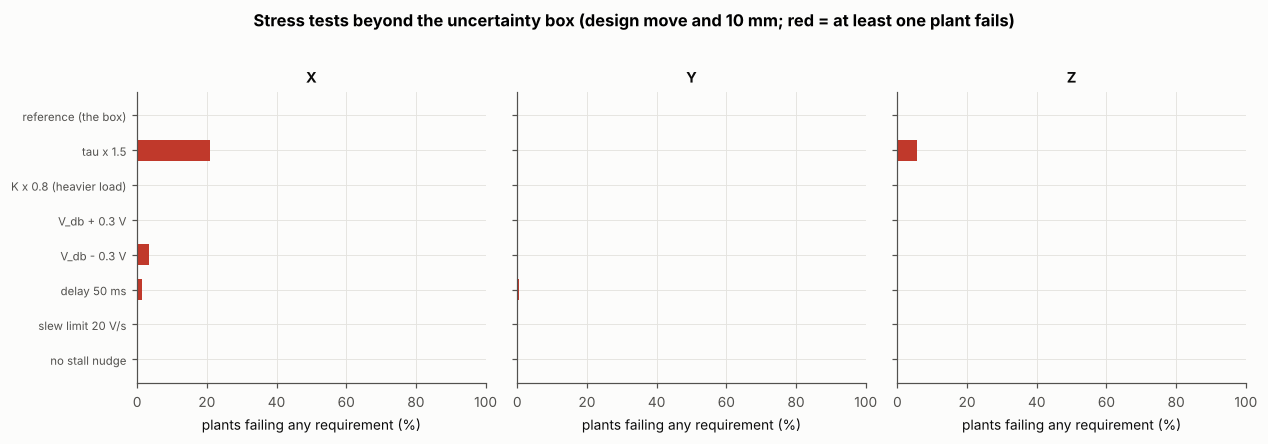

In [17]:
def m_scale(key, f):
    def _m(S):
        S = {k: v.copy() for k, v in S.items()}; S[key] = S[key] * f; return S
    return _m

def m_add(key, d):
    def _m(S):
        S = {k: v.copy() for k, v in S.items()}; S[key] = S[key] + d; return S
    return _m

STRESS = [
    ('reference (the box)', None, {}),
    ('tau x 1.5', m_scale('tau', 1.5), {}),
    ('K x 0.8 (heavier load)', m_scale('K', 0.8), {}),
    ('V_db + 0.3 V', m_add('Vdb', 0.3), {}),
    ('V_db - 0.3 V', m_add('Vdb', -0.3), {}),
    ('delay 50 ms', m_add('delay_ms', 35.0), {}),
    ('slew limit 20 V/s', None, {'slew': 20.0}),
    ('no stall nudge', None, {'nudge_rate': 0.0}),
]
rows = []
for a in 'XYZ':
    mv = (TIME_D[a], 10.0 if TIME_D[a] != 10.0 else 3.0)
    for name, mod, kw in STRESS:
        S, r, J = verify(a, tuple(sorted(set(mv))), mod=mod, **kw)
        rows.append({'axis': a, 'case': name, 'plants': len(J), 'failing': int(J.fail.sum()),
                     'worst settle (s)': J.t_rest.replace(np.inf, np.nan).max() if (J.t_rest < np.inf).any() else np.inf,
                     'not finished': int((~J.ok_done).sum()),
                     'worst overshoot (mm)': J.over_fb.max(), 'outside one count': int((~J.ok_band).sum()), 'late (> 3 s)': int((~J.ok_time).sum())})
STRESSDF = pd.DataFrame(rows)
display(STRESSDF.set_index(['axis', 'case']).round(2))

fig, axs = plt.subplots(1, 3, figsize=(11.6, 3.9), sharey=False)
for j, a in enumerate('XYZ'):
    d = STRESSDF[STRESSDF.axis == a]
    ax = axs[j]
    y = np.arange(len(d))[::-1]
    ax.barh(y, d['failing'] / d['plants'] * 100, color=[BAD if f > 0 else AXC[a] for f in d['failing']], height=0.6)
    ax.set_yticks(y); ax.set_yticklabels(d['case'], fontsize=7.5)
    ax.set_xlabel('plants failing any requirement (%)'); ax.set_title(f'{a}')
    ax.set_xlim(0, 100)
    if j > 0:
        ax.set_yticklabels([])
fig.suptitle('Stress tests beyond the uncertainty box (design move and 10 mm; red = at least one plant fails)', y=1.02, fontweight='bold')
fig.tight_layout()
save(fig, 'D10_stress.png')

In [18]:
# --- Vlim options with the other gains held ---
OPT = {'X': [4.5, 5.0, 6.0, 8.0], 'Y': [6.0, 7.0, 8.0], 'Z': [4.0, 5.0, 6.0, 8.0]}
rows = []
for a in 'XYZ':
    for vl in OPT[a]:
        g = dict(GAINS[a]); g['Vlim'] = vl
        S, r, J = verify(a, tuple(MOVES_SPEC[a]), gains=g)
        S2, r2, J2 = verify(a, (LONG[a],), level='coarse', gains=g, t_max={'X': 80.0, 'Y': 80.0, 'Z': 150.0}[a])
        b = BOX[a]
        rows.append({'axis': a, 'Vlim (V)': vl, 'failing plants (all moves)': int(J.fail.sum()), 'worst overshoot (mm)': J.over_fb.max(),
                     'long move (mm)': LONG[a], 'worst long-move time (s)': J2.t_rest.max(),
                     'free coast at best-plant cruise (mm)': b['K'][2] * (vl - b['Vdb'][0]) * b['tau'][2]})
VLIMDF = pd.DataFrame(rows)
display(VLIMDF.set_index(['axis', 'Vlim (V)']).round(2))

failing plants (all moves)  worst overshoot (mm)  long move (mm)  worst long-move time (s)  free coast at best-plant cruise (mm)
axis Vlim (V)                                                                                                                                  
X    4.5                              109                  1.06           600.0                     31.16                                  4.43
     5.0                                0                  1.06           600.0                     25.62                                  5.23
     6.0                                0                  1.06           600.0                     19.05                                  6.81
     8.0                                0                  1.06           600.0                     12.90                                  9.99
Y    6.0                                0                  1.05          1000.0                     50.35                                  1.98
     7.0                                0                  1.05          1000.0                     35.74                                  2.61
     8.0                                0                  1.05          1000.0                     27.79                                  3.25
Z    4.0                              165                  0.27           200.0                    103.15                                  0.79
     5.0                                0                  0.27           200.0                     58.81                                  1.17
     6.0                                0                  0.27           200.0                     45.40                                  1.55
     8.0                                0                  0.27           200.0                     31.48                                  2.30

**Reading the Vlim table.** Y needs 8 V for MECH-09. X passes from 5 V. On Z, 4 V is not enough drive for the high end of the box ($V_{db}$ up to 2.7 V, $K$ down to 1.5); 5 V is the lowest limit that passes and is also the highest voltage at which the
identified Z law holds. The 6 V and 8 V rows pass in the model, which represents the 8 V mean speed with a knee at 5 V, but the measured 8 V motion alternates between about 6 and 14 mm/s within a run, so a higher limit cuts the
worst-case 200 mm traverse from 59 s to 31 s in simulation, at the cost of an operating point the identification has not validated.

## 9. What the firmware default would do on the new plants

The bench note in the firmware document gives `gain_y = [0.3, 0.05, 7.0, 2.0]` ($K_p$, $K_d$, $V_{lim}$, $V_0$) with the remark that jogs stalled at $V_0$ = 0. The identified Y dead band is 3.09 V, so $V_0$ = 2.0 V leaves the drive
1.1 V short of moving the carriage: only the stall nudge (2 V/s after 150 ms without a pulse) can start it, and it has to ramp the drive up from 2.0 V each time the carriage stops. Figure D11 shows what that does.

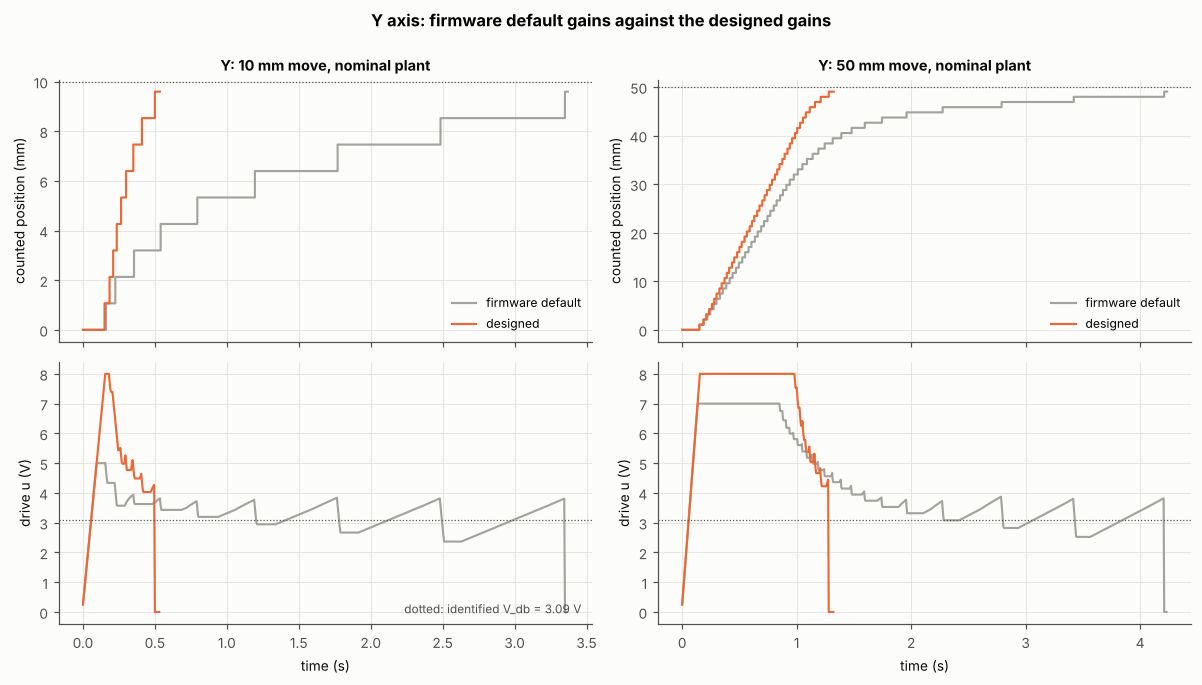

,failing plants,of,not finished in 12 s,late (> 3 s),outside one count,worst settle at 50 mm (s)
Y gains,,,,,,
"firmware default [0.3, 0.05, 7, 2.0]",1295,1944,0,1295,0,7.20
designed,0,1944,0,0,0,1.85


In [19]:
DEF_Y = dict(Kp=0.3, Kd=0.05, Vlim=7.0, V0=2.0)
fig, axs = plt.subplots(2, 2, figsize=(11.0, 6.2), sharex='col')
for col, (D, tmx) in enumerate(((10.0, 8.0), (50.0, 8.0))):
    for gname, g, colr in (('firmware default', DEF_Y, MUTED), ('designed', GAINS['Y'], AXC['Y'])):
        t, T, r = trace('Y', G('Y', g), D, dVb=0.3, delay=15.0, t_max=tmx)
        axs[0, col].step(t, T['n'] * SLOT['Y'], where='post', color=colr, label=gname)
        axs[1, col].plot(t, T['u'], color=colr, label=gname)
    axs[0, col].axhline(D, color=INK_2, lw=0.8, ls=':')
    axs[0, col].set_title(f'Y: {D:.0f} mm move, nominal plant'); axs[0, col].set_ylabel('counted position (mm)')
    axs[1, col].axhline(BOX['Y']['Vdb0'], color=INK_2, lw=0.8, ls=':'); axs[1, col].set_ylabel('drive u (V)'); axs[1, col].set_xlabel('time (s)')
    axs[0, col].legend(loc='lower right')
note(axs[1, 0], 'dotted: identified V_db = 3.09 V', 'br')
fig.suptitle('Y axis: firmware default gains against the designed gains', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D11_default_vs_designed.png')

rows = []
for nm, g in (('firmware default [0.3, 0.05, 7, 2.0]', DEF_Y), ('designed', GAINS['Y'])):
    S, r, J = verify('Y', (3.0, 10.0, 25.0, 50.0), gains=g, t_max=12.0)
    rows.append({'Y gains': nm, 'failing plants': int(J.fail.sum()), 'of': len(J), 'not finished in 12 s': int((~J.ok_done).sum()),
                 'late (> 3 s)': int((~J.ok_time).sum()), 'outside one count': int((~J.ok_band).sum()),
                 'worst settle at 50 mm (s)': J[J.D0 == 50.0].t_rest.replace(np.inf, np.nan).max()})
DEFDF = pd.DataFrame(rows).set_index('Y gains')
display(DEFDF.round(2))

## 10. Linear check of the chosen gains (S and Z domain)

For completeness, the same linear analysis as Sections 2 and 3 is applied to the final gains: closed-loop poles over the corners of the box and the delays, in the S plane and at $T=5$ ms. This checks the part of the
behaviour that the linear model can see (stability and damping of the loop with an ideal speed signal). It does not see the quantisation, which Section 6 covers.

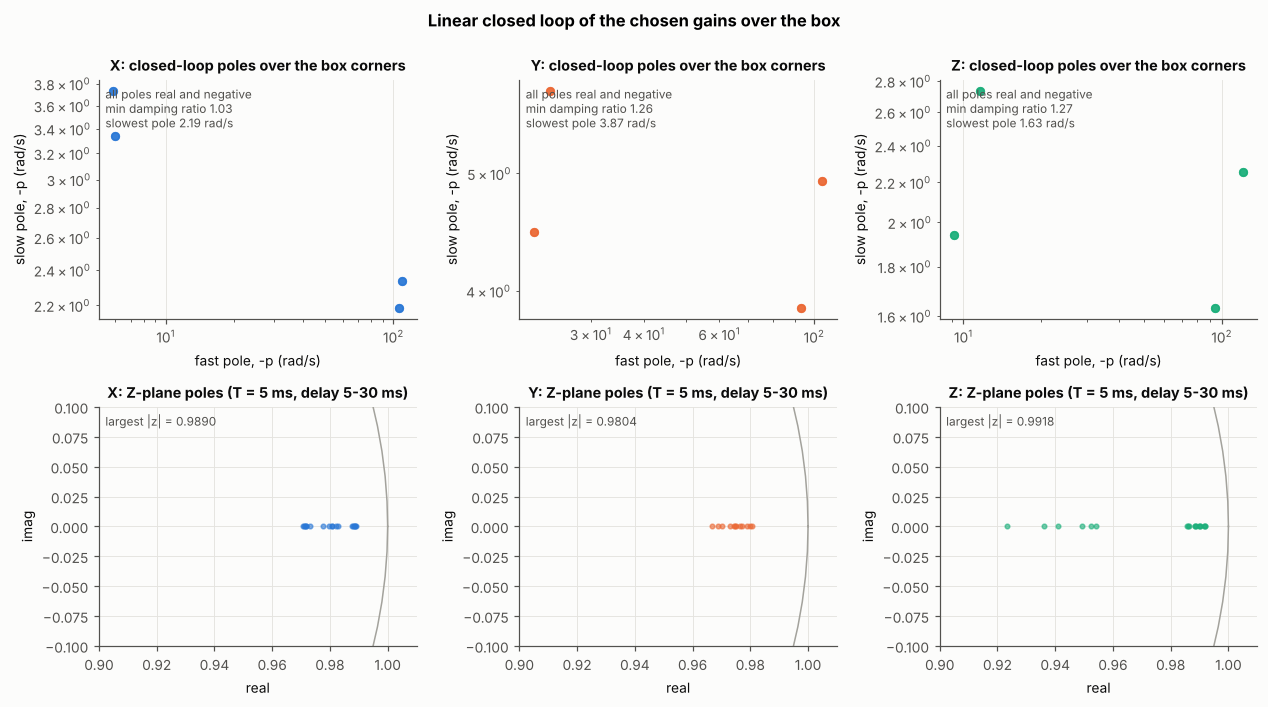

,min damping ratio (linear),slowest pole (rad/s),largest |z| at 5 ms with delay,omega_n nominal (rad/s)
axis,,,,
X,1.026,2.186,0.989,5.259
Y,1.260,3.873,0.980,14.341
Z,1.272,1.632,0.992,6.632


In [20]:
rows = []
fig, axs = plt.subplots(2, 3, figsize=(11.6, 6.4))
for j, a in enumerate('XYZ'):
    g = GAINS[a]; b = BOX[a]
    P = []; Zp = []
    zmax = 0.0; zmin = 9.0; wmin = 1e9
    for K, tau, d in corners(a):
        p = cl_poles(K, tau, g['Kp'], g['Kd']); P.append(p)
        wn = np.sqrt(K * g['Kp'] / tau); zeta = (1 + K * g['Kd']) / (2 * np.sqrt(K * g['Kp'] * tau))
        zmin = min(zmin, zeta); wmin = min(wmin, float(np.min(np.abs(p.real))))
        z = cl_matrix_z(K, tau, g['Kp'], g['Kd'], d); zmax = max(zmax, float(np.max(np.abs(z)))); Zp.append(z[np.abs(z) > 0.3])
    P = np.concatenate(P); Zp = np.concatenate(Zp)
    ax = axs[0, j]
    pr = np.sort(P.real.reshape(-1, 2), axis=1)                 # (fast, slow) real poles of each corner
    ax.plot(-pr[:, 0], -pr[:, 1], 'o', color=AXC[a], alpha=0.6, ms=5)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(f'{a}: closed-loop poles over the box corners'); ax.set_xlabel('fast pole, -p (rad/s)'); ax.set_ylabel('slow pole, -p (rad/s)')
    note(ax, f'all poles real and negative\nmin damping ratio {zmin:.2f}\nslowest pole {wmin:.2f} rad/s', 'tl')
    ax = axs[1, j]
    th = np.linspace(0, 2 * np.pi, 300)
    ax.plot(np.cos(th), np.sin(th), color=MUTED, lw=1)
    ax.plot(Zp.real, Zp.imag, '.', color=AXC[a], alpha=0.6)
    ax.set_xlim(0.9, 1.01); ax.set_ylim(-0.1, 0.1)
    ax.set_title(f'{a}: Z-plane poles (T = 5 ms, delay 5-30 ms)'); ax.set_xlabel('real'); ax.set_ylabel('imag')
    note(ax, f'largest |z| = {zmax:.4f}', 'tl')
    rows.append({'axis': a, 'min damping ratio (linear)': zmin, 'slowest pole (rad/s)': wmin, 'largest |z| at 5 ms with delay': zmax,
                 'omega_n nominal (rad/s)': np.sqrt(b['K'][1] * g['Kp'] / (float(ident.loc[a, 'tau_design_ms']) / 1e3))})
fig.suptitle('Linear closed loop of the chosen gains over the box', y=0.995, fontweight='bold')
fig.tight_layout()
save(fig, 'D12_linear_check.png')
LINDF = pd.DataFrame(rows).set_index('axis')
display(LINDF.round(3))

**Reading Figure D12.** The linear model is stable with a large margin on every corner and delay: all closed-loop poles are real and negative (damping ratio at least 1.03, so no oscillation in the linear loop) and the largest $|z|$ at 5 ms is
0.98 to 0.99. The speed term is what keeps the corners with a large τ overdamped. The overshoot that remains in the full simulation (up to one count) therefore does not come from an oscillation: it is the distance the carriage coasts after the stop trigger
(speed at the trigger × τ), which depends on $V_0$ and on the quantisation. A linear design alone would not have found the $V_0$ values: they come from the dead band and the stall behaviour, which the linear loop does not contain.

## 11. Requirement check and gain table

In [21]:
def no_reversal_check(a):
    S, r, J = verify(a, (TIME_D[a],), record=486)
    tr = r['traj']
    dn = np.diff(tr['n'], axis=1)
    return float(np.nanmin(tr['u'])) >= 0.0 and float(np.nanmin(tr['v'])) >= -1e-9 and float(np.nanmin(dn)) >= 0.0

rows = []
for a in 'XYZ':
    V = VER[a]
    dd = TIME_D[a]
    v = V.loc[dd]
    allw = VERJ[a]
    to_ratio = (allw.t_rest / np.array([timeout_s(a, d) for d in allw.D0])).max()
    nr = no_reversal_check(a)
    rows.append({'axis': a, 'requirement': 'CTRL-04 settle <= 3 s, within one count', 'moves': f'up to {dd:g} mm', 'worst case': f"{v['worst settle (s)']:.2f} s, {v['worst short of target (counts)']:.2f} counts", 'limit': '3 s, 1 count',
                 'pass': bool(v['settle > 3 s'] == 0 and allw[allw.D0 <= dd].ok_band.all())})
    rows.append({'axis': a, 'requirement': 'CTRL-07 overshoot <= 1.1 mm', 'moves': 'all listed moves', 'worst case': f"{allw.over_fb.max():.2f} mm", 'limit': '1.1 mm', 'pass': bool(allw.over_fb.max() <= OVER_SPEC)})
    rows.append({'axis': a, 'requirement': 'CTRL-07 no reversal of the drive', 'moves': 'all listed moves', 'worst case': 'u >= 0, speed >= 0, count never decreases' if nr else 'reversal found', 'limit': 'none', 'pass': nr})
    rows.append({'axis': a, 'requirement': 'CTRL-08 finish before the timeout', 'moves': 'all listed and long', 'worst case': f"{max(to_ratio, (LONGT.loc[a, 'worst time / timeout'])):.2f} of the timeout", 'limit': '1.00', 'pass': bool(max(to_ratio, LONGT.loc[a, 'worst time / timeout']) < 1)})
    rows.append({'axis': a, 'requirement': 'CTRL-08 overshoot inside the 5 mm soft-limit margin', 'moves': 'all listed and long', 'worst case': f"{max(allw.over_fb.max(), LONGJ[a].over_fb.max()):.2f} mm", 'limit': '5 mm', 'pass': bool(max(allw.over_fb.max(), LONGJ[a].over_fb.max()) < 5.0)})
rows.append({'axis': 'Y', 'requirement': 'MECH-09 1 m in <= 30 s', 'moves': '1000 mm', 'worst case': f"{LONGT.loc['Y', 'worst time (s)']:.1f} s", 'limit': '30 s', 'pass': bool(LONGT.loc['Y', 'worst time (s)'] <= T_TRAV)})
COMP = pd.DataFrame(rows)
COMP['pass'] = COMP['pass'].map({True: 'pass', False: 'FAIL'})
display(COMP.set_index(['axis', 'requirement']))

moves                                 worst case         limit  pass
axis requirement                                                                                                                           
X    CTRL-04 settle <= 3 s, within one count                     up to 50 mm                        2.53 s, 1.00 counts  3 s, 1 count  pass
     CTRL-07 overshoot <= 1.1 mm                            all listed moves                                    1.06 mm        1.1 mm  pass
     CTRL-07 no reversal of the drive                       all listed moves  u >= 0, speed >= 0, count never decreases          none  pass
     CTRL-08 finish before the timeout                   all listed and long                        0.09 of the timeout          1.00  pass
     CTRL-08 overshoot inside the 5 mm soft-limit ma...  all listed and long                                    1.06 mm          5 mm  pass
Y    CTRL-04 settle <= 3 s, within one count                     up to 50 mm                        1.85 s, 1.00 counts  3 s, 1 count  pass
     CTRL-07 overshoot <= 1.1 mm                            all listed moves                                    1.05 mm        1.1 mm  pass
     CTRL-07 no reversal of the drive                       all listed moves  u >= 0, speed >= 0, count never decreases          none  pass
     CTRL-08 finish before the timeout                   all listed and long                        0.08 of the timeout          1.00  pass
     CTRL-08 overshoot inside the 5 mm soft-limit ma...  all listed and long                                    1.05 mm          5 mm  pass
Z    CTRL-04 settle <= 3 s, within one count                      up to 5 mm                        2.18 s, 1.00 counts  3 s, 1 count  pass
     CTRL-07 overshoot <= 1.1 mm                            all listed moves                                    0.27 mm        1.1 mm  pass
     CTRL-07 no reversal of the drive                       all listed moves  u >= 0, speed >= 0, count never decreases          none  pass
     CTRL-08 finish before the timeout                   all listed and long                        0.27 of the timeout          1.00  pass
     CTRL-08 overshoot inside the 5 mm soft-limit ma...  all listed and long                                    0.27 mm          5 mm  pass
Y    MECH-09 1 m in <= 30 s                                          1000 mm                                     27.8 s          30 s  pass

In [22]:
# --- export the tables ---
pd.DataFrame({a: {'Kp': GAINS[a]['Kp'], 'Kd': GAINS[a]['Kd'], 'Vlim': GAINS[a]['Vlim'], 'V0': GAINS[a]['V0']} for a in 'XYZ'}).T.rename_axis('axis').to_csv(RES / 'gains_firmware_format.csv')
(RES / 'gain_commands.txt').write_text('\n'.join(f"gain_{a.lower()} = [{GAINS[a]['Kp']:g}, {GAINS[a]['Kd']:g}, {GAINS[a]['Vlim']:g}, {GAINS[a]['V0']:g}]   # [Kp (V/mm), Kd (V per mm/s), Vlim (V), V0 (V)]" for a in 'XYZ') + '\n')
pd.concat({a: VER[a] for a in 'XYZ'}, names=['axis']).to_csv(RES / 'verification_by_move.csv')
STRESSDF.to_csv(RES / 'stress_tests.csv', index=False)
VLIMDF.to_csv(RES / 'vlim_options.csv', index=False)
LONGT.to_csv(RES / 'long_moves.csv')
COMP.to_csv(RES / 'requirement_check.csv', index=False)
DEFDF.to_csv(RES / 'firmware_default_vs_designed_Y.csv')
LINDF.to_csv(RES / 'linear_check.csv')
pd.concat({a: CURVE[a] for a in 'XYZ'}, names=['axis', 'move (mm)']).to_csv(RES / 'settle_vs_move_length.csv')
pd.DataFrame({a: {'K lo': BOX[a]['K'][0], 'K nom': BOX[a]['K'][1], 'K hi': BOX[a]['K'][2], 'tau lo (s)': BOX[a]['tau'][0], 'tau mid (s)': BOX[a]['tau'][1], 'tau hi (s)': BOX[a]['tau'][2],
                  'Vdb lo': BOX[a]['Vdb'][0], 'Vdb nom': BOX[a]['Vdb'][1], 'Vdb hi': BOX[a]['Vdb'][2]} for a in 'XYZ'}).T.rename_axis('axis').to_csv(RES / 'plant_boxes.csv')
for a in 'XYZ':
    SEARCH[a]['R1'].to_csv(RES / f'search_refined_{a}.csv')
    SEARCH[a]['R0'].to_csv(RES / f'search_coarse_{a}.csv')

## Gains

The table is the result of this notebook. Paste the lines into the firmware configuration in the `[Kp, Kd, Vlim, V0]` order used by `gain_y` in the firmware notes.

In [23]:
display(Markdown('```\n' + '\n'.join(f"gain_{a.lower()} = [{GAINS[a]['Kp']:g}, {GAINS[a]['Kd']:g}, {GAINS[a]['Vlim']:g}, {GAINS[a]['V0']:g}]" for a in 'XYZ') + '\n```'))

```
gain_x = [0.35, 0.053, 6, 2.46]
gain_y = [0.637, 0.051, 8, 3.97]
gain_z = [1.7, 0.391, 5, 3.1]
```